# Credit Card Default — Exploratory Data Analysis

**Part 1 of 3 of the credit-default-prediction project**

| Step | Notebook | Goal |
|---|---|---|
| **1. Explore** | `01_data_exploration.ipynb` *(this notebook)* | Understand every variable, test our assumptions, locate the predictive signal and the data-quality issues |
| 2. Curate | `02_data_curation.ipynb` | Fix invalid codes, treat duplicates and outliers, transform skewed variables, engineer features |
| 3. Model | `03_classifiers.ipynb` | Train, tune and compare classifiers |

**Dataset.** 30,000 credit card holders of a Taiwanese bank, observed from April to September 2005 (Yeh & Lien, 2009 — UCI *default of credit card clients*). The target tells whether the client **defaulted on the October 2005 payment**.

**How to read this notebook.** It goes from simple to ambitious: sanity checks and one-variable views first, then relationships with the target, time dynamics, multivariate structure, and finally a one-page dashboard. Every analysis follows the same pattern:

> **Method** (markdown) → **Code** → **Result and interpretation** (markdown)

Assumptions are written explicitly as **H1, H2, …** and each one receives a verdict: **confirmed**, **rejected** or **nuanced**. Every section ends with what it means for the future classifier.

### Contents
1. Loading the data
2. First look and data quality
3. The target
4. Univariate analysis
5. Each feature versus default
6. The time dimension (6 months of history)
7. Multivariate structure
8. Which features carry the signal?
9. Geometry of the classes (PCA, t-SNE)
10. Outliers and anomalies
11. Executive dashboard
12. Conclusions and roadmap

## 0. Setup

`pandas`/`numpy` for data handling, `matplotlib`/`seaborn` for the charts, `scipy` for the statistical tests and `scikit-learn` for mutual information, PCA, t-SNE and anomaly detection.

One colour convention is used everywhere: **blue = no default**, **red = default**.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.gridspec import GridSpec
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

RANDOM_STATE = 42
DATA_PATH = Path('data') / 'credit_default.csv'
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

C_OK, C_DEF, C_NEUTRAL = '#2E86AB', '#E4572E', '#5B6C8F'
PALETTE = {0: C_OK, 1: C_DEF}
LABELS = {0: 'No default', 1: 'Default'}

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

**Helper functions.**

- `default_rate` / `plot_default_rate`: default rate per group with a **95% Wilson confidence interval**. Wilson is preferred over the usual normal approximation because some groups are tiny (e.g. undocumented categories with fewer than 100 clients), where the normal interval is unreliable.
- `cramers_v`: effect size of a chi-squared test (0 = independent, 1 = perfectly associated). With 30,000 rows almost any difference is *statistically significant*, so we need an effect size to judge whether it is *practically* useful.
- `compare_classes`: medians per class, Mann–Whitney U test (non-parametric, robust to skewness) and univariate ROC-AUC (0.5 = useless, 1 = perfect ranking).
- `slog`: signed logarithm `sign(x) · log(1 + |x|)`, which compresses heavy tails while keeping zeros and negative amounts.

In [2]:
def wilson_ci(k, n, z=1.96):
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def default_rate(data, col, target='DEFAULT'):
    g = data.groupby(col, observed=True)[target].agg(n='size', defaults='sum')
    g['rate'] = g['defaults'] / g['n']
    g['ci_low'], g['ci_high'] = wilson_ci(g['defaults'], g['n'])
    return g


def plot_default_rate(data, col, ax, labels=None, title=None, color=None, show_n=True):
    g = default_rate(data, col)
    x = np.arange(len(g))
    ax.bar(x, g['rate'], color=color or C_DEF, alpha=0.85, edgecolor='white')
    ax.errorbar(x, g['rate'], yerr=[g['rate'] - g['ci_low'], g['ci_high'] - g['rate']],
                fmt='none', ecolor='#333333', capsize=3, lw=1)
    ax.axhline(BASE_RATE, ls='--', color='grey', lw=1)
    ax.set_xticks(x, [str(labels.get(v, v)) if labels else str(v) for v in g.index])
    if show_n:
        for xi, (top, n) in enumerate(zip(g['ci_high'], g['n'])):
            ax.text(xi, top + 0.01, f'n={n:,}', ha='center', va='bottom', fontsize=7, color='#555555')
        ax.set_ylim(0, g['ci_high'].max() * 1.15 + 0.02)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
    ax.set_ylabel('Default rate')
    ax.set_xlabel('')
    if title:
        ax.set_title(title)
    return g


def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return v, chi2, p


def compare_classes(col, data=None):
    data = df if data is None else data
    a = data.loc[data['DEFAULT'] == 0, col]
    b = data.loc[data['DEFAULT'] == 1, col]
    p = stats.mannwhitneyu(a, b).pvalue
    auc = roc_auc_score(data['DEFAULT'], data[col])
    fmt = lambda v: f'{v:,.0f}' if abs(v) >= 100 else f'{v:.3f}'
    print(f'{col:>15}: median no-default = {fmt(a.median()):>8} | median default = {fmt(b.median()):>8} '
          f'| Mann-Whitney p = {p:.1e} | univariate ROC-AUC = {max(auc, 1 - auc):.3f}')


def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))


def k_fmt(v):
    return f'{v / 1000:,.0f}k'

## 1. Loading the data

**H1 — The CSV is a standard table with a single header line.**

Before trusting the defaults of `pd.read_csv`, we look at the raw text.

In [3]:
with open(DATA_PATH, encoding='utf-8') as f:
    for _ in range(3):
        print(f.readline().rstrip())

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1


**H1 — rejected.** The file has **two header lines**: a generic one (`X1 … X23, Y`) and the real variable names. We load it with `header=1` and apply two renamings:

- `PAY_0` → `PAY_1`: the original names jump from `PAY_0` to `PAY_2`. After renaming, the suffix *k* refers to the **same month** in `PAY_k`, `BILL_AMTk` and `PAY_AMTk` (1 = September, …, 6 = April).
- `default payment next month` → `DEFAULT`.

In [4]:
df = (pd.read_csv(DATA_PATH, header=1)
        .rename(columns={'PAY_0': 'PAY_1', 'default payment next month': 'DEFAULT'}))
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

30,000 rows x 25 columns


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. First look and data quality

### 2.1 Data dictionary (UCI documentation)

| Variable | Meaning | Kind | Documented values |
|---|---|---|---|
| `ID` | Client identifier | key | — |
| `LIMIT_BAL` | Credit granted, individual + family (supplementary) credit | continuous, NT$ | — |
| `SEX` | Gender | nominal | 1 = male, 2 = female |
| `EDUCATION` | Education level | nominal / ordinal | 1 = graduate school, 2 = university, 3 = high school, 4 = others |
| `MARRIAGE` | Marital status | nominal | 1 = married, 2 = single, 3 = others |
| `AGE` | Age in years | discrete | — |
| `PAY_1 … PAY_6` | Repayment status in Sep, Aug, Jul, Jun, May, Apr 2005 | ordinal | −1 = paid duly, 1 = 1-month delay, …, 9 = 9+ months delay |
| `BILL_AMT1 … BILL_AMT6` | Bill statement amount, Sep → Apr 2005 | continuous, NT$ | — |
| `PAY_AMT1 … PAY_AMT6` | Amount paid, Sep → Apr 2005 | continuous, NT$ | — |
| `DEFAULT` | Default on the October 2005 payment | **binary target** | 1 = yes, 0 = no |

Suffix 1 is the **most recent** month (September 2005) and suffix 6 the oldest (April 2005). Amounts are in New Taiwan dollars (about 32 NT$ per US$ in 2005).

We define the variable groups once and use them everywhere.

In [5]:
TARGET = 'DEFAULT'
PAY_STATUS = [f'PAY_{k}' for k in range(1, 7)]
BILL = [f'BILL_AMT{k}' for k in range(1, 7)]
PAY_AMT = [f'PAY_AMT{k}' for k in range(1, 7)]
DEMO_CAT = ['SEX', 'EDUCATION', 'MARRIAGE']
MONTHS = ['Sep', 'Aug', 'Jul', 'Jun', 'May', 'Apr']
CHRONO = MONTHS[::-1]

SEX_LABELS = {1: 'Male', 2: 'Female'}
EDU_LABELS = {0: '0 (?)', 1: 'Graduate', 2: 'University', 3: 'High school', 4: 'Others', 5: '5 (?)', 6: '6 (?)'}
MAR_LABELS = {0: '0 (?)', 1: 'Married', 2: 'Single', 3: 'Others'}

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_1      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   30000 non-nu

**Result.** 30,000 clients, 25 columns, all stored as 64-bit integers (≈ 5.7 MB). Even `SEX`, `EDUCATION` and `MARRIAGE`, which are **nominal**, are integers: a model that reads `EDUCATION = 4` as *twice* `EDUCATION = 2` would be wrong. How to encode them is a decision for the curation notebook.

### 2.2 Completeness and uniqueness

- **H2** — There are no missing values.
- **H3** — `ID` is a unique key.
- **H4** — Every row is a different client (no duplicated records).

In [6]:
features = df.drop(columns=['ID', TARGET])
pd.Series({
    'Missing values (all cells)': df.isna().sum().sum(),
    'ID is unique': df['ID'].is_unique,
    'Duplicated rows, ignoring ID': df.drop(columns='ID').duplicated().sum(),
    'Duplicated feature vectors, ignoring ID and target': features.duplicated().sum(),
}, dtype=object).to_frame('value')

,value
Missing values (all cells),0
ID is unique,True
"Duplicated rows, ignoring ID",35
"Duplicated feature vectors, ignoring ID and target",56


In [7]:
dup_mask = features.duplicated(keep=False)
dup_groups = (df[dup_mask]
              .groupby(list(features.columns))[TARGET]
              .agg(copies='size', distinct_labels='nunique', defaults='sum')
              .reset_index())
inactive = (df[dup_mask][BILL + PAY_AMT] == 0).all(axis=1)
print(f'{dup_mask.sum()} rows belong to {len(dup_groups)} groups of identical feature vectors; '
      f'{(dup_groups.distinct_labels > 1).sum()} groups have contradictory labels.')
print(f'{inactive.mean():.0%} of these rows have every bill and every payment equal to 0.')
dup_groups[['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'BILL_AMT1', 'PAY_AMT1',
            'copies', 'defaults', 'distinct_labels']].sort_values('copies', ascending=False).head(8)

108 rows belong to 52 groups of identical feature vectors; 21 groups have contradictory labels.


90% of these rows have every bill and every payment equal to 0.


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,BILL_AMT1,PAY_AMT1,copies,defaults,distinct_labels
0,20000,1,2,2,24,2,1650,0,3,2,2
47,360000,2,1,2,27,1,0,0,3,1,2
34,210000,2,2,1,49,1,0,0,3,1,2
27,200000,2,1,1,34,1,0,0,3,1,2
4,80000,1,1,2,37,1,0,0,2,1,2
5,80000,1,3,2,27,1,0,0,2,1,2
6,80000,2,2,1,31,-2,0,0,2,0,1
7,80000,2,2,2,25,-2,0,0,2,0,1


**Result.**

- **H2 — confirmed.** No missing values at all.
- **H3 — confirmed.** `ID` is unique, but it is a pure row number with no meaning, so it must **never be used as a feature**.
- **H4 — nuanced.** 35 rows are exact copies of another row (every column except `ID`), and 56 rows repeat the *features* of another row. Altogether 108 rows form 52 groups of identical clients, and **21 groups have contradictory labels** (same features, one copy defaulted and the other did not). 90% of these rows are *inactive* accounts (every bill and payment equal to 0): once all amounts are zero, only the demographics and the statuses remain to tell clients apart, so many of these may be different people with the same simple profile rather than copy errors.
  - *Curation:* drop the exact duplicates (otherwise a copy can land in the training set and its twin in the test set).
  - *Modelling:* the contradictory groups are **irreducible noise**: no model can classify both copies correctly.

### 2.3 Do the codes match the documentation?

**H5 — Categorical and ordinal variables only take the documented values.**

In [8]:
documented = {
    'SEX': {1, 2},
    'EDUCATION': {1, 2, 3, 4},
    'MARRIAGE': {1, 2, 3},
    **{c: {-1, *range(1, 10)} for c in PAY_STATUS},
}
rows = []
for col, allowed in documented.items():
    counts = df[col].value_counts()
    unknown = counts[~counts.index.isin(list(allowed))]
    rows.append({'variable': col,
                 'observed values': sorted(counts.index.tolist()),
                 'undocumented values': sorted(unknown.index.tolist()),
                 'rows affected': int(unknown.sum()),
                 '% of rows': round(100 * unknown.sum() / len(df), 2)})
pd.DataFrame(rows).set_index('variable')

,observed values,undocumented values,rows affected,% of rows
variable,,,,
SEX,"[1, 2]",[],0,0.00
EDUCATION,"[0, 1, 2, 3, 4, 5, 6]","[0, 5, 6]",345,1.15
MARRIAGE,"[0, 1, 2, 3]",[0],54,0.18
PAY_1,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",17496,58.32
PAY_2,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",19512,65.04
PAY_3,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",19849,66.16
PAY_4,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",20803,69.34
PAY_5,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",21493,71.64
PAY_6,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]","[-2, 0]",21181,70.60


**H5 — rejected.** Two different problems:

1. `EDUCATION` takes the values **0, 5 and 6** (345 clients, 1.2%) and `MARRIAGE` the value **0** (54 clients). They are rare, and the natural fix is to merge them into the existing *others* category.
2. All `PAY_k` contain **−2 and 0**, which are not documented. They are not rare: **0 is the most frequent status** every month. These codes cannot be dropped, they have to be understood.

An explanation of the codes circulates among users of this dataset: **−2 = no consumption** (card not used), **−1 = balance paid in full**, **0 = revolving credit** (minimum payment made, the rest carried over). We will not take it on faith:

**H6 — If that explanation holds, status −2 goes with near-zero bills and status 0 with large outstanding bills.**

In [9]:
df.groupby('PAY_1').agg(
    clients=('ID', 'size'),
    median_bill_sep=('BILL_AMT1', 'median'),
    share_bill_zero_or_negative=('BILL_AMT1', lambda s: (s <= 0).mean()),
    median_paid_sep=('PAY_AMT1', 'median'),
    default_rate=(TARGET, 'mean'),
).round(3)

,clients,median_bill_sep,share_bill_zero_or_negative,median_paid_sep,default_rate
PAY_1,,,,,
-2,2759,1179.0,0.327,1131.0,0.132
-1,5686,2739.5,0.001,1732.5,0.168
0,14737,49605.0,0.000,3000.0,0.128
1,3688,4606.5,0.458,0.0,0.339
2,2667,41632.0,0.000,2000.0,0.691
3,322,18354.0,0.000,0.0,0.758
4,76,31633.0,0.000,0.0,0.684
5,26,39752.5,0.000,0.0,0.500
6,11,71310.0,0.000,0.0,0.545


**H6 — confirmed.**

- Status **−2** has the smallest median bill (1,179 NT$) and a third of these clients have a zero or negative September bill: consistent with *no consumption*.
- Status **0** has by far the largest median bill (49,605 NT$) and a payment much smaller than the bill (median 3,000): consistent with *revolving credit*, the client pays part of the bill and carries the rest.
- Status **−1** sits in between, with small bills that are mostly paid in full.

Two more lessons from this table:

- The *no delay* codes are **not ordered by risk**: −1 (paid in full) defaults at 16.8%, more than 0 (revolving) at 12.8%. Using `PAY_k` as a plain number assumes that −2 < −1 < 0 means increasing risk, which is false.
- From status 1 onwards the risk jumps: 33.9% at status 1, 69.1% at status 2. Oddly, 45.8% of the clients with status 1 in September have a zero or negative bill, a *one-month delay* on no debt. First hint that status 1 is special.

**H7 — The PAY coding is the same every month.** If the six `PAY_k` columns are the same measurement at six dates, the frequency of each status should be similar from month to month.

In [10]:
STATUS_ORDER = sorted(pd.unique(df[PAY_STATUS].values.ravel()))
status_by_month = (pd.concat({m: df[c].value_counts() for c, m in zip(PAY_STATUS, MONTHS)}, axis=1)
                     .reindex(STATUS_ORDER).fillna(0).astype(int))
status_by_month.index.name = 'status'
status_by_month

,Sep,Aug,Jul,Jun,May,Apr
status,,,,,,
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19


**H7 — rejected.** Status **1** (one-month delay) is used **3,688 times in September** but only 28, 4, 2, 0 and 0 times in the five previous months, while status 2 is common every month. Real behaviour cannot change that abruptly: from April to August a first missed payment was apparently recorded **directly as 2**. So `PAY_1 = 1` and `PAY_2 = 1` do not mean the same thing.

**Data-quality takeaways (for the curation notebook):**

| Issue | Size | Proposed action |
|---|---|---|
| Double header | file level | `header=1` *(done)* |
| `ID` meaningless | 1 column | drop before modelling |
| Exact duplicates | 35 rows | drop |
| Undocumented `EDUCATION` 0/5/6, `MARRIAGE` 0 | 399 rows | merge into *others* |
| Undocumented PAY codes −2/0 | most rows | keep, they are meaningful; consider one-hot or a *delay months* + *usage type* split |
| `PAY_1 = 1` coded differently | 3,688 rows | prefer month-comparable features such as *is delayed (≥ 1)* |

## 3. The target

**H8 — Default is the minority class.** Most clients pay their bill; the question is *how* imbalanced the classes are, because it decides the evaluation metrics.

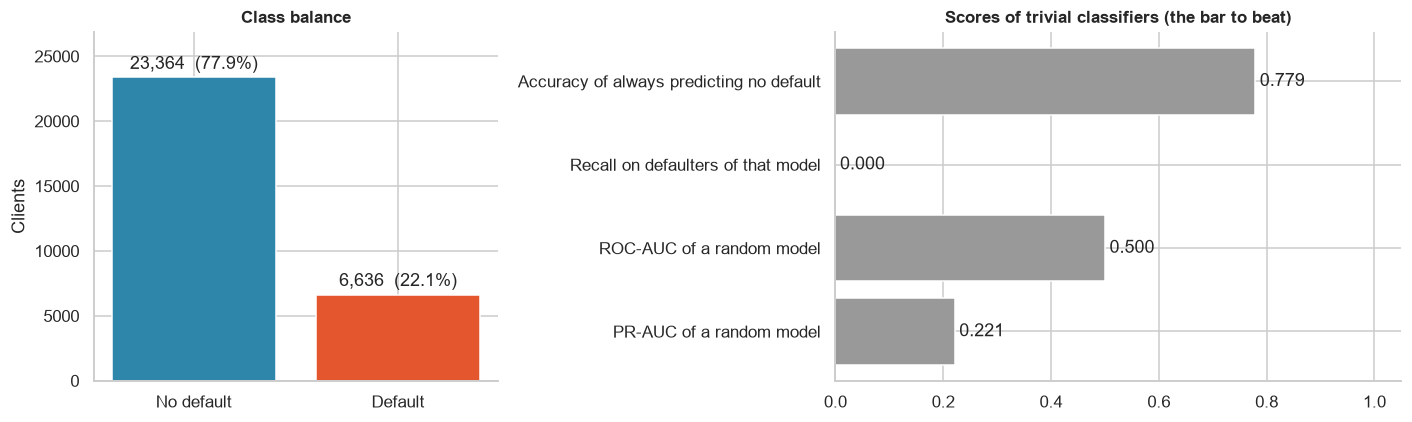

Default rate = 22.12%  |  imbalance ratio = 3.52 : 1


In [11]:
BASE_RATE = df[TARGET].mean()
counts = df[TARGET].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1.4]})
bars = axes[0].bar([LABELS[i] for i in counts.index], counts.values, color=[PALETTE[i] for i in counts.index])
axes[0].bar_label(bars, labels=[f'{v:,}  ({v / len(df):.1%})' for v in counts.values], padding=3)
axes[0].set_ylim(0, counts.max() * 1.15)
axes[0].set_title('Class balance')
axes[0].set_ylabel('Clients')

trivial = pd.Series({
    'Accuracy of always predicting no default': 1 - BASE_RATE,
    'Recall on defaulters of that model': 0.0,
    'ROC-AUC of a random model': 0.5,
    'PR-AUC of a random model': BASE_RATE,
})
bars = axes[1].barh(trivial.index[::-1], trivial.values[::-1], color=['#999999', '#999999', C_DEF, '#999999'])
axes[1].bar_label(bars, labels=[f'{v:.3f}' for v in trivial.values[::-1]], padding=3)
axes[1].set_xlim(0, 1.05)
axes[1].set_title('Scores of trivial classifiers (the bar to beat)')
plt.tight_layout()
plt.show()
print(f'Default rate = {BASE_RATE:.2%}  |  imbalance ratio = {counts[0] / counts[1]:.2f} : 1')

**H8 — confirmed.** 22.1% of clients default (6,636 out of 30,000), an imbalance of about **3.5 : 1**. It is moderate (fraud datasets are often 1 : 1000), but it is enough to make accuracy misleading:

- A model that **never** predicts default reaches **77.9% accuracy** while being useless (recall 0 on defaulters).
- For the modelling notebook: use **stratified** train/test splits and cross-validation, report **ROC-AUC, PR-AUC (baseline 0.22), recall/precision/F1 on the default class**, and consider `class_weight='balanced'` or resampling (resampling only inside the training folds, never before the split).
- The decision threshold should be tuned, not left at 0.5: in credit, a missed defaulter (false negative) usually costs much more than a refused good client.

## 4. Univariate analysis

### 4.1 Credit limit and age

**Method.** Histogram + kernel density estimate (shape), box plot (spread and outliers by the 1.5 × IQR rule) and skewness (0 = symmetric, > 1 = strongly right-skewed).

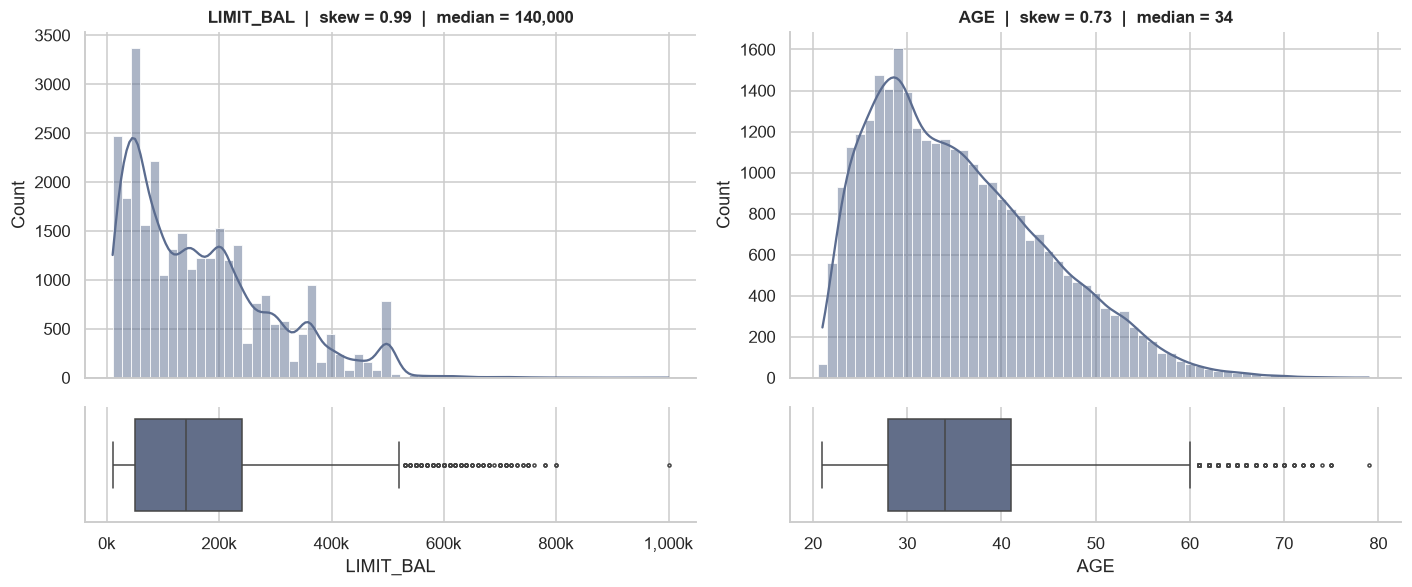

Most frequent credit limits: 50k (3,365), 20k (1,976), 30k (1,610), 80k (1,567), 200k (1,528), 150k (1,110)
Share of limits that are a multiple of 10,000 NT$: 100.0%


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 5.5), gridspec_kw={'height_ratios': [3, 1]}, sharex='col')
for j, col in enumerate(['LIMIT_BAL', 'AGE']):
    bins = 60 if col == 'LIMIT_BAL' else np.arange(20.5, 80.5, 1)
    sns.histplot(df[col], bins=bins, kde=True, ax=axes[0, j], color=C_NEUTRAL)
    sns.boxplot(x=df[col], ax=axes[1, j], color=C_NEUTRAL, fliersize=2)
    axes[0, j].set_title(f'{col}  |  skew = {df[col].skew():.2f}  |  median = {df[col].median():,.0f}')
axes[1, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: k_fmt(v)))
plt.tight_layout()
plt.show()

top_limits = df['LIMIT_BAL'].value_counts().head(6)
round_share = (df['LIMIT_BAL'] % 10_000 == 0).mean()
print('Most frequent credit limits:', ', '.join(f'{k_fmt(k)} ({v:,})' for k, v in top_limits.items()))
print(f'Share of limits that are a multiple of 10,000 NT$: {round_share:.1%}')
df[['LIMIT_BAL', 'AGE']].describe().T.round(1)

**Result.**

- `LIMIT_BAL` ranges from 10,000 to 1,000,000 NT$ (median 140,000) and is moderately right-skewed (0.99). **Every** limit is a multiple of 10,000 and a few values dominate (50k alone covers 11% of the clients): the bank grants limits from a grid, so the variable is quasi-discrete. The box plot flags clients above ≈ 525k as outliers, but they are simply the bank's best customers, not errors.
- `AGE` ranges from 21 to 79 (median 34) with a long right tail; half of the clients are between 28 and 41. No impossible value (no minors, no 150-year-olds).

### 4.2 Demographic categories

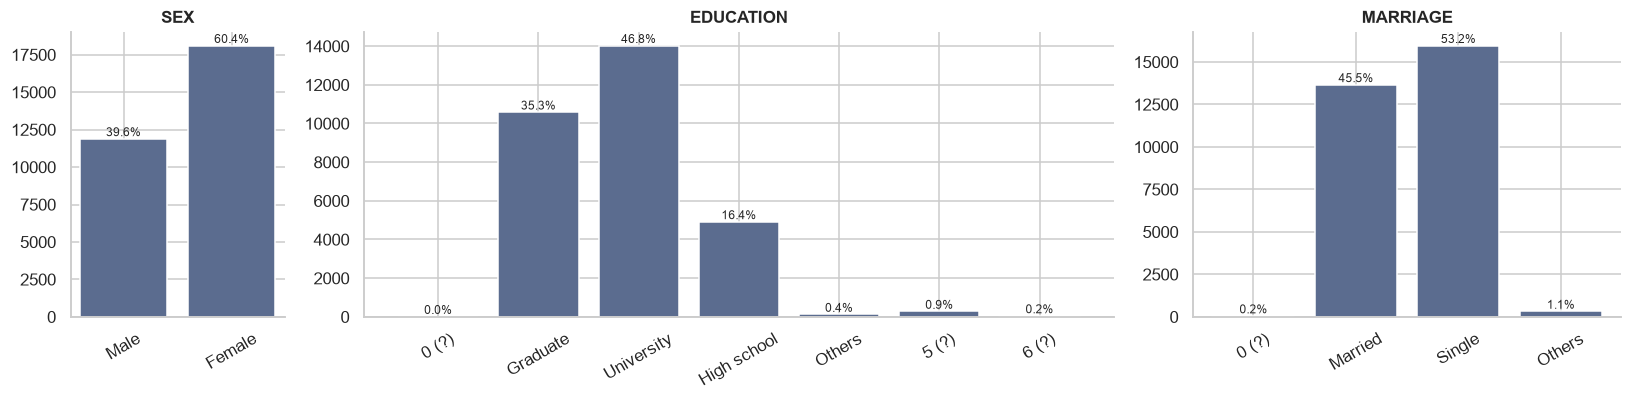

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={'width_ratios': [2, 7, 4]})
for ax, (col, labels) in zip(axes, [('SEX', SEX_LABELS), ('EDUCATION', EDU_LABELS), ('MARRIAGE', MAR_LABELS)]):
    vc = df[col].value_counts().sort_index()
    bars = ax.bar([labels[v] for v in vc.index], vc.values, color=C_NEUTRAL)
    ax.bar_label(bars, labels=[f'{v / len(df):.1%}' for v in vc.values], fontsize=8)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Result.** 60% of the clients are women. Education is dominated by university (47%) and graduate school (35%), which is plausible for credit card holders. Married (46%) and single (53%) clients are balanced. The undocumented codes are visible as tiny bars: they are too small to estimate reliable statistics, another argument for merging them.

### 4.3 Bill and payment amounts

**H9 — Monetary amounts are strongly right-skewed with heavy tails** (a few very large accounts), as is typical of income and spending data.

In [14]:
money = ['LIMIT_BAL'] + BILL + PAY_AMT
pd.DataFrame({
    'skewness': df[money].skew(),
    'kurtosis': df[money].kurt(),
    '% zeros': 100 * (df[money] == 0).mean(),
    '% negative': 100 * (df[money] < 0).mean(),
    'min': df[money].min(),
    'median': df[money].median(),
    'p99': df[money].quantile(0.99),
    'max': df[money].max(),
}).round(2)

,skewness,kurtosis,% zeros,% negative,min,median,p99,max
LIMIT_BAL,0.99,0.54,0.00,0.00,10000,140000.0,500000.00,1000000
BILL_AMT1,2.66,9.81,6.69,1.97,-165580,22381.5,350110.68,964511
BILL_AMT2,2.71,10.30,8.35,2.23,-69777,21200.0,337495.28,983931
BILL_AMT3,3.09,19.78,9.57,2.18,-157264,20088.5,325030.39,1664089
BILL_AMT4,2.82,11.31,10.65,2.25,-170000,19052.0,304997.27,891586
BILL_AMT5,2.88,12.31,11.69,2.18,-81334,18104.5,285868.33,927171
BILL_AMT6,2.85,12.27,13.40,2.29,-339603,17071.0,279505.06,961664
PAY_AMT1,14.67,415.25,17.50,0.00,0,2100.0,66522.18,873552
PAY_AMT2,30.45,1641.63,17.99,0.00,0,2009.0,76651.02,1684259
PAY_AMT3,17.22,564.31,19.89,0.00,0,1800.0,70000.00,896040


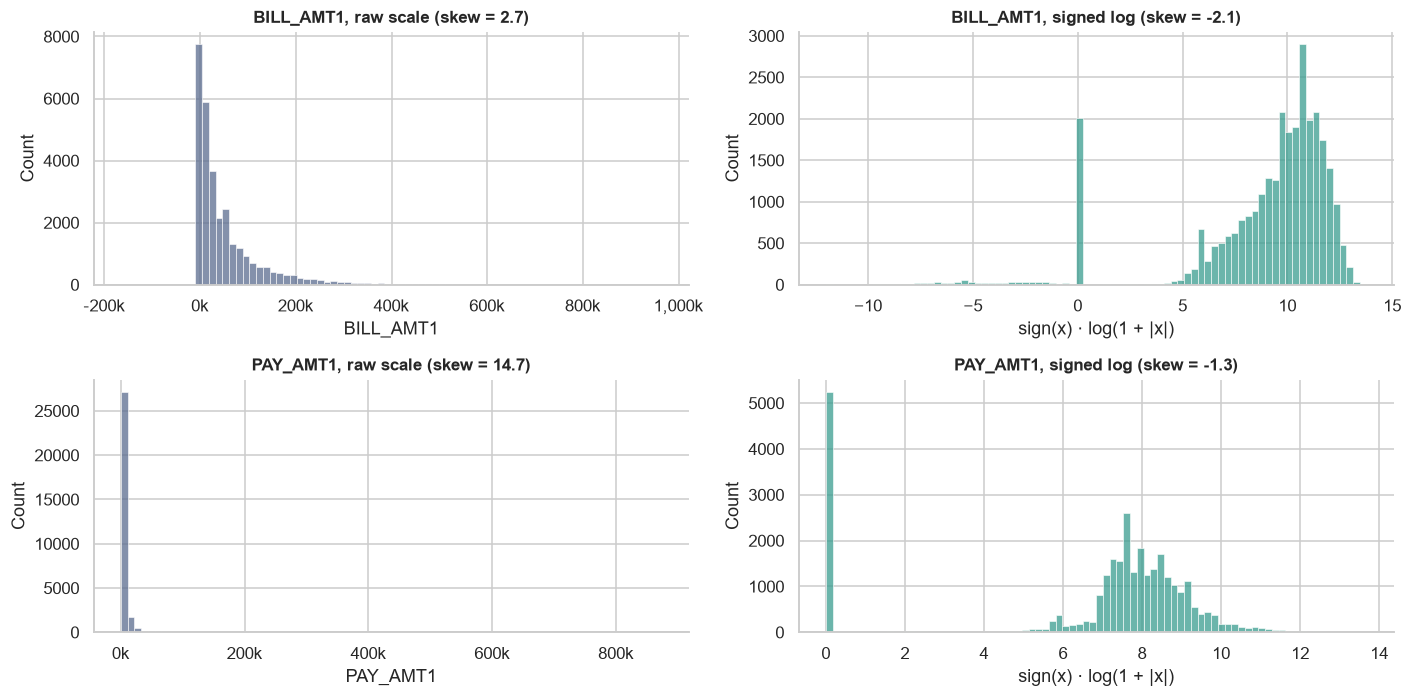

Clients with at least one negative bill: 1,930 (6.4%)


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5))
for i, col in enumerate(['BILL_AMT1', 'PAY_AMT1']):
    sns.histplot(df[col], bins=80, ax=axes[i, 0], color=C_NEUTRAL)
    axes[i, 0].set_title(f'{col}, raw scale (skew = {df[col].skew():.1f})')
    axes[i, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: k_fmt(v)))
    sns.histplot(slog(df[col]), bins=80, ax=axes[i, 1], color='#3A9D8F')
    axes[i, 1].set_title(f'{col}, signed log (skew = {slog(df[col]).skew():.1f})')
    axes[i, 1].set_xlabel('sign(x) · log(1 + |x|)')
plt.tight_layout()
plt.show()

neg_clients = (df[BILL] < 0).any(axis=1)
print(f'Clients with at least one negative bill: {neg_clients.sum():,} ({neg_clients.mean():.1%})')

**H9 — confirmed, very strongly for payments.**

- Bills have a skewness of 2.7–3.1; payments 10–30, with a kurtosis up to 1,600: a handful of clients paid more than 800,000 NT$ in one month while the median payment is about 2,000.
- Zeros are frequent: 7–13% of the bills and **17–24% of the payments** are exactly 0. These zeros are information (*nothing was paid*), not missing data.
- **1,930 clients (6.4%) have at least one negative bill**, down to −340k. A negative statement means the bank owes the client money (overpayment or refund). Unusual but legitimate, so it must not be *fixed* by taking an absolute value.
- The signed log turns the payments into a compact bell shape plus a separate spike at 0, and the bills into a bell shape plus a spike at 0 and a small negative tail. The remaining skewness (−1.3 and −2.1) now comes from the zero spike, not from extreme values.

**For curation:** a *signed log + is-zero indicator* representation is better than raw amounts for linear and distance-based models. Tree-based models are insensitive to monotonic transformations and can use the raw values.

### 4.4 Repayment status over the six months

**Method.** For each month, the share of clients in each repayment status, as a stacked bar (chronological order, April → September). Grey/green/blue are the *no delay* codes, the reds are delays of increasing length.

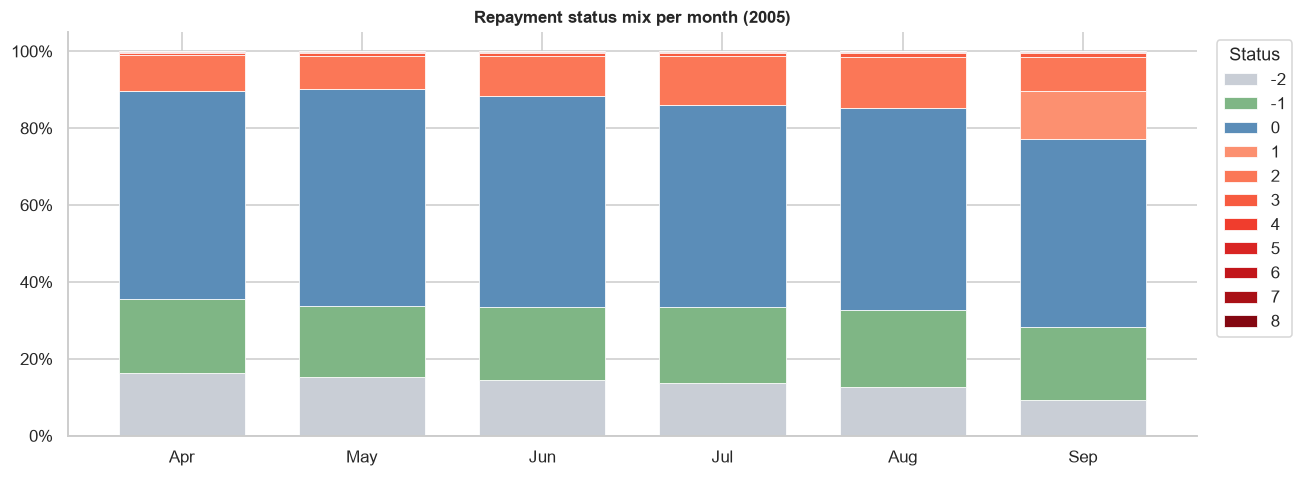

Share of clients with a delay (status >= 1): Apr 10.3%, May 9.9%, Jun 11.7%, Jul 14.0%, Aug 14.8%, Sep 22.7%


In [16]:
STATUS_COLORS = {-2: '#C9CED6', -1: '#7FB685', 0: '#5B8DB8',
                 **{k: plt.cm.Reds(0.3 + 0.08 * k) for k in range(1, 10)}}
share = (pd.concat({m: df[c].value_counts(normalize=True) for c, m in zip(PAY_STATUS, MONTHS)}, axis=1)
           .reindex(STATUS_ORDER).fillna(0)[CHRONO])

fig, ax = plt.subplots(figsize=(12, 4.5))
bottom = np.zeros(share.shape[1])
for status in share.index:
    ax.bar(share.columns, share.loc[status], bottom=bottom, color=STATUS_COLORS[status],
           label=str(status), edgecolor='white', lw=0.5, width=0.7)
    bottom += share.loc[status].values
ax.legend(title='Status', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_title('Repayment status mix per month (2005)')
plt.tight_layout()
plt.show()

delayed = (df[PAY_STATUS] >= 1).mean().set_axis(MONTHS)[CHRONO]
print('Share of clients with a delay (status >= 1):', ', '.join(f'{m} {v:.1%}' for m, v in delayed.items()))

**Result.** Every month, 77–90% of the clients are in a *no delay* status (−2, −1 or 0), and status 0 (revolving) alone covers about half. The share of clients in delay rises from about 10% in April–May to 14–15% in July–August, then **jumps to 22.7% in September**, largely because of the new status 1 found in H7. Part of the rise may be a real deterioration (2005 is the period of Taiwan's credit and cash card debt crisis), but the data cannot separate it from the coding change.

**Section 4 takeaways:** credit limits come from a grid, ages are plausible, monetary amounts are heavy-tailed with many meaningful zeros and some legitimate negatives, and most clients are never late.

## 5. Each feature versus default

**Method.**

- *Categorical / ordinal features*: default rate per level with its 95% Wilson interval; the dashed line is the overall default rate (22.1%). A chi-squared test checks independence and Cramér's V measures the strength.
- *Continuous features*: density per class, Mann–Whitney U test (do the two classes have the same distribution?) and univariate ROC-AUC (how well the raw feature alone ranks defaulters above non-defaulters).

### 5.1 Demographics

- **H10** — Men default more often than women.
- **H11** — The higher the education, the lower the default rate.
- **H12** — Marital status has an effect (married clients carry more household obligations).

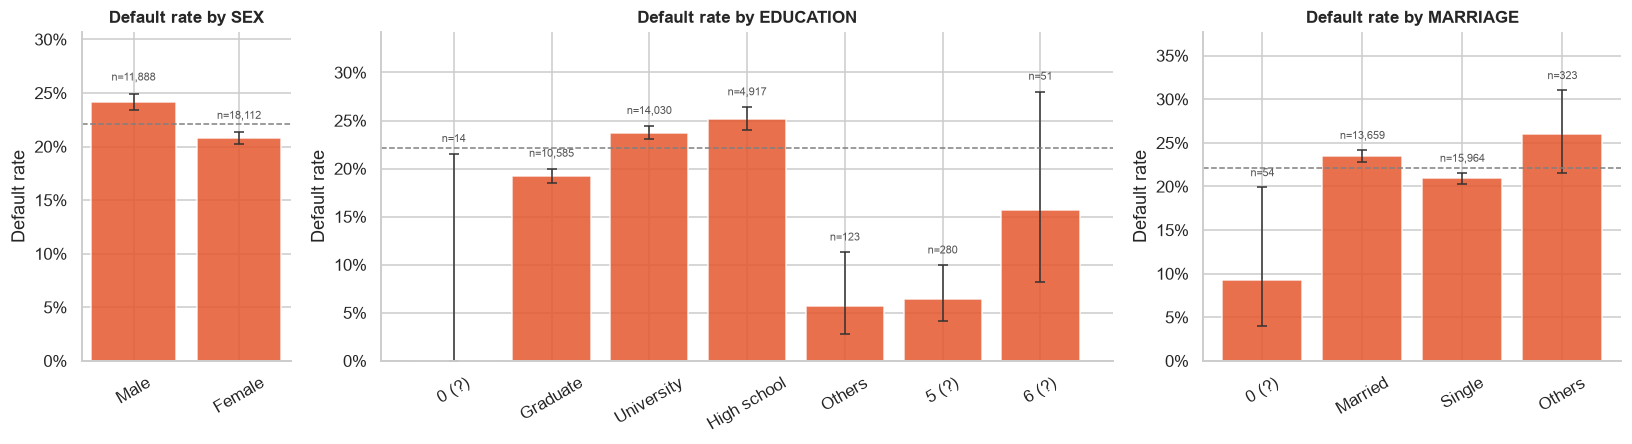

,cramers_v,chi2,p_value
SEX,0.039878,47.708797,4.944679e-12
EDUCATION,0.073760,163.216558,1.233263e-32
MARRIAGE,0.034478,35.662396,8.825862e-08


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2, 7, 4]})
for ax, (col, labels) in zip(axes, [('SEX', SEX_LABELS), ('EDUCATION', EDU_LABELS), ('MARRIAGE', MAR_LABELS)]):
    plot_default_rate(df, col, ax, labels=labels, title=f'Default rate by {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

pd.DataFrame({col: dict(zip(['cramers_v', 'chi2', 'p_value'], cramers_v(df[col], df[TARGET])))
              for col in DEMO_CAT}).T

**Result.**

- **H10 — confirmed, but weak.** Men default at 24.2% vs 20.8% for women (p ≈ 5·10⁻¹²), yet Cramér's V is only 0.04.
- **H11 — confirmed for the documented levels.** Graduate 19.2% < university 23.7% < high school 25.2%. The *others* and undocumented levels 0 and 5 show very low rates (0–6%), and level 6 sits at 16% with an interval spanning roughly 8–28%. Merging them into *others* is reasonable, but it creates a small **low-risk** group rather than a neutral one.
- **H12 — confirmed, but weak.** Married 23.5% vs single 20.9%, V = 0.03.

**Takeaway:** with 30,000 rows every p-value is tiny, but the effect sizes are small (V < 0.08). Demographics are **weak predictors** on their own; they may still matter in interaction with other variables (section 7.3). They also raise a **fairness** question: using sex or marital status to grant credit is restricted in many jurisdictions, so the modelling notebook should compare models with and without them.

### 5.2 Credit limit

**H13 — Clients with a lower credit limit default more.** The bank grants limits after its own risk assessment, so `LIMIT_BAL` should already contain part of the answer.

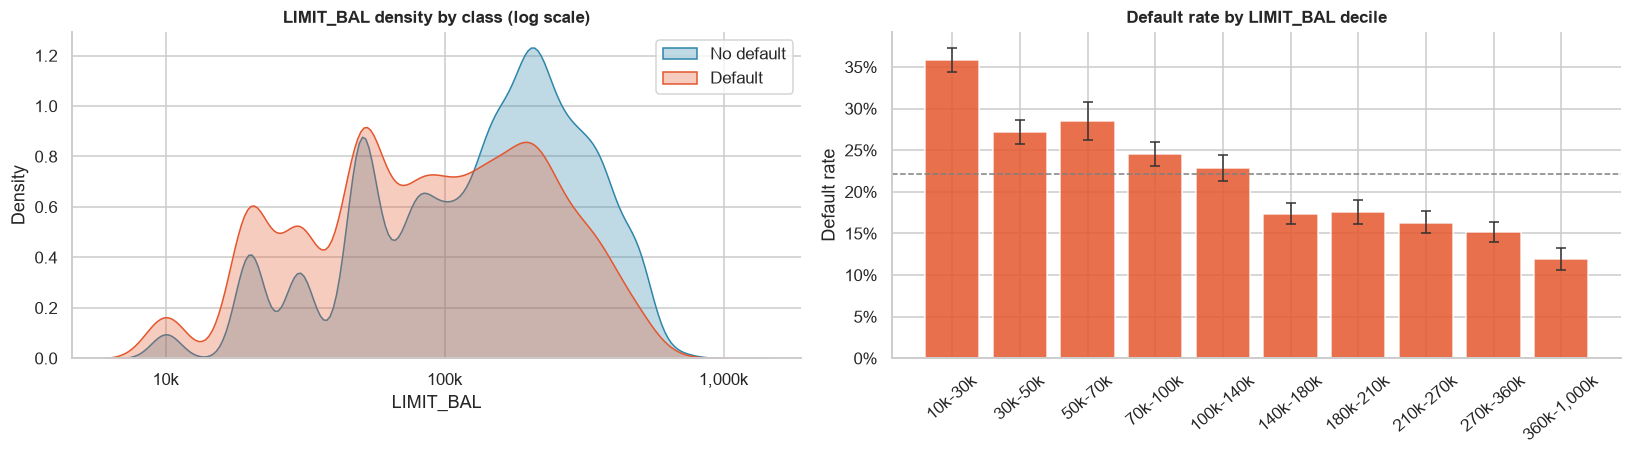

      LIMIT_BAL: median no-default =  150,000 | median default =   90,000 | Mann-Whitney p = 1.2e-189 | univariate ROC-AUC = 0.618


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for cls in (0, 1):
    sns.kdeplot(df.loc[df[TARGET] == cls, 'LIMIT_BAL'], ax=axes[0], color=PALETTE[cls], fill=True,
                alpha=0.3, label=LABELS[cls], log_scale=True)
axes[0].legend()
axes[0].set_title('LIMIT_BAL density by class (log scale)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: k_fmt(v)))

limit_decile = pd.qcut(df['LIMIT_BAL'], 10)
decile_labels = {iv: f'{k_fmt(iv.left)}-{k_fmt(iv.right)}' for iv in limit_decile.cat.categories}
plot_default_rate(df.assign(LIMIT_DECILE=limit_decile), 'LIMIT_DECILE', axes[1], labels=decile_labels,
                  title='Default rate by LIMIT_BAL decile', show_n=False)
axes[1].tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.show()
compare_classes('LIMIT_BAL')

**H13 — confirmed, with a strong and almost monotonic effect.** The default rate falls from **35.8%** in the lowest decile (≤ 30k) to **11.9%** in the highest (> 360k). Median limit: 150k for non-defaulters vs 90k for defaulters; univariate ROC-AUC 0.62. On the left, defaulters are over-represented below 50k and non-defaulters dominate above 150k.

`LIMIT_BAL` is predictive although it says nothing about behaviour, because it already reflects the bank's own risk assessment at the time the card was granted.

### 5.3 Age

**H14 — Younger clients default more, and risk decreases steadily with age.**

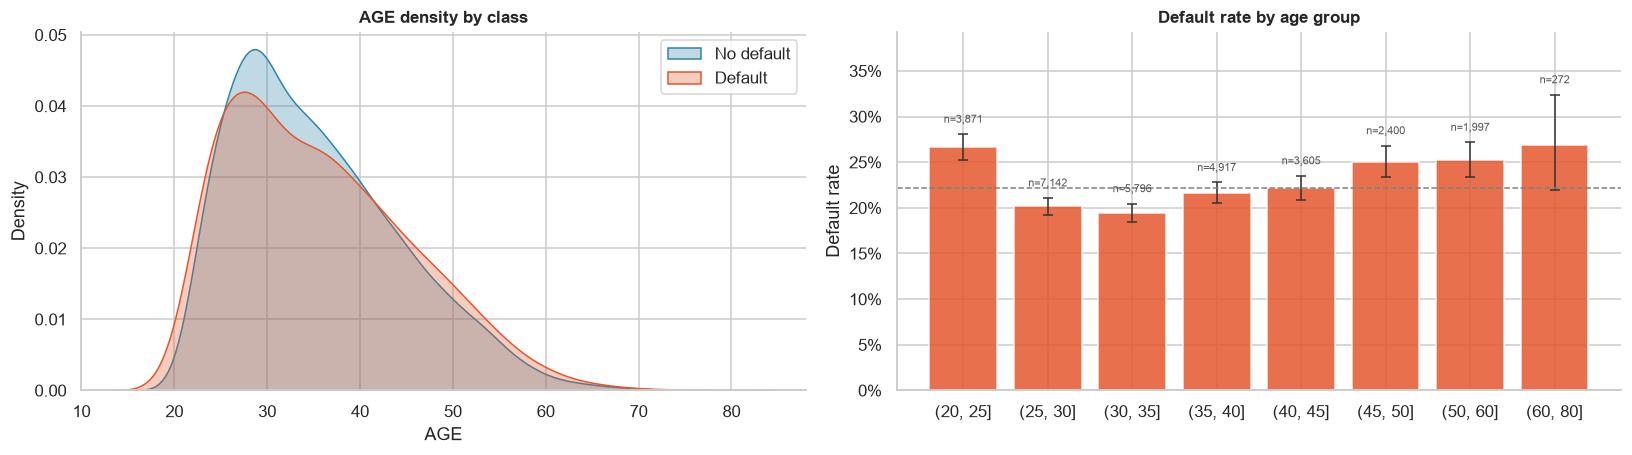

            AGE: median no-default =   34.000 | median default =   34.000 | Mann-Whitney p = 3.7e-01 | univariate ROC-AUC = 0.504
Univariate ROC-AUC of |AGE - 33| (distance to the low-risk age): 0.535


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for cls in (0, 1):
    sns.kdeplot(df.loc[df[TARGET] == cls, 'AGE'], ax=axes[0], color=PALETTE[cls], fill=True,
                alpha=0.3, label=LABELS[cls], bw_adjust=1.5)
axes[0].legend()
axes[0].set_title('AGE density by class')

age_group = pd.cut(df['AGE'], [20, 25, 30, 35, 40, 45, 50, 60, 80])
plot_default_rate(df.assign(AGE_GROUP=age_group), 'AGE_GROUP', axes[1], title='Default rate by age group')
plt.tight_layout()
plt.show()

compare_classes('AGE')
age_gap = (df['AGE'] - 33).abs()
print(f'Univariate ROC-AUC of |AGE - 33| (distance to the low-risk age): {roc_auc_score(df[TARGET], age_gap):.3f}')

**H14 — rejected as stated, replaced by a U-shape.** The two age distributions are almost identical (same median 34, Mann–Whitney p = 0.37, ROC-AUC 0.50): a test of *location* finds nothing. Yet the default rate by age group is clearly **U-shaped**: 26.7% at 21–25, a minimum around 19–20% between 26 and 35, then back to 25–27% after 45. A monotonic term cannot capture this, while the simple distance to the low-risk age, |AGE − 33|, already reaches a ROC-AUC of 0.535.

**Lesson:** a non-significant test means *no shift of the median*, not *no information*. For linear models, age should be binned or given a squared term; tree-based models will find the U-shape on their own.

### 5.4 Repayment status

**H15 — Payment history is the strongest predictor, and the most recent month (`PAY_1`) matters most.** This is the central intuition of credit scoring: *past delays predict future defaults*.

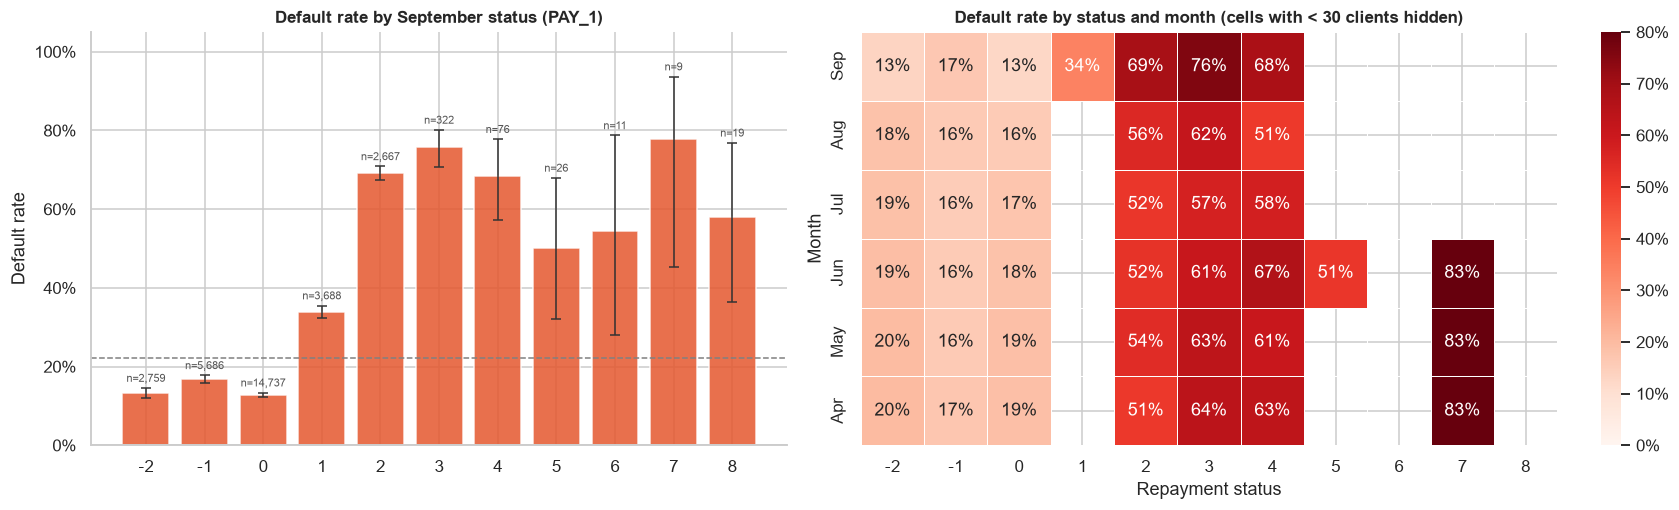

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
cramers_v,0.422925,0.340317,0.295661,0.279373,0.270659,0.250788
chi2,5365.964977,3474.466790,2622.462128,2341.469945,2197.694901,1886.835309
p_value,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 1.25]})
plot_default_rate(df, 'PAY_1', axes[0], title='Default rate by September status (PAY_1)')
axes[0].set_ylim(0, 1.05)

rates = pd.concat({m: df.groupby(c)[TARGET].mean() for c, m in zip(PAY_STATUS, MONTHS)}, axis=1)
sizes = pd.concat({m: df[c].value_counts() for c, m in zip(PAY_STATUS, MONTHS)}, axis=1)
rates = rates.where(sizes >= 30).reindex(STATUS_ORDER)
sns.heatmap(rates.T, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=0.8, linewidths=0.5, ax=axes[1],
            cbar_kws={'format': mticker.PercentFormatter(1)})
axes[1].set_title('Default rate by status and month (cells with < 30 clients hidden)')
axes[1].set_xlabel('Repayment status')
axes[1].set_ylabel('Month')
plt.tight_layout()
plt.show()

pd.DataFrame({c: dict(zip(['cramers_v', 'chi2', 'p_value'], cramers_v(df[c], df[TARGET]))) for c in PAY_STATUS})

**H15 — confirmed. This is by far the strongest signal in the data.**

- Clients without delay in September default at 13–17%. With one month of delay: **34%**, two months: **69%**, three months: **76%**. Beyond three months the groups are tiny (76 clients or fewer) and the rates are noisy.
- The heatmap shows the same pattern every month, with an effect that fades as we go back in time: Cramér's V decreases steadily from **0.42 (September)** to 0.34, 0.30, 0.28, 0.27 and **0.25 (April)**. Recent behaviour matters most, but older months still carry information.
- Within the *no delay* codes the order is not monotonic (−1 is riskier than −2 and 0), confirming that PAY should not be fed to a linear model as a plain number. Splitting it into *months of delay* (`max(PAY, 0)`) plus a *usage type* category (−2 / −1 / 0) keeps both pieces of information.

### 5.5 Bill and payment amounts

**H16 — Clients with larger bills (more debt) default more.**

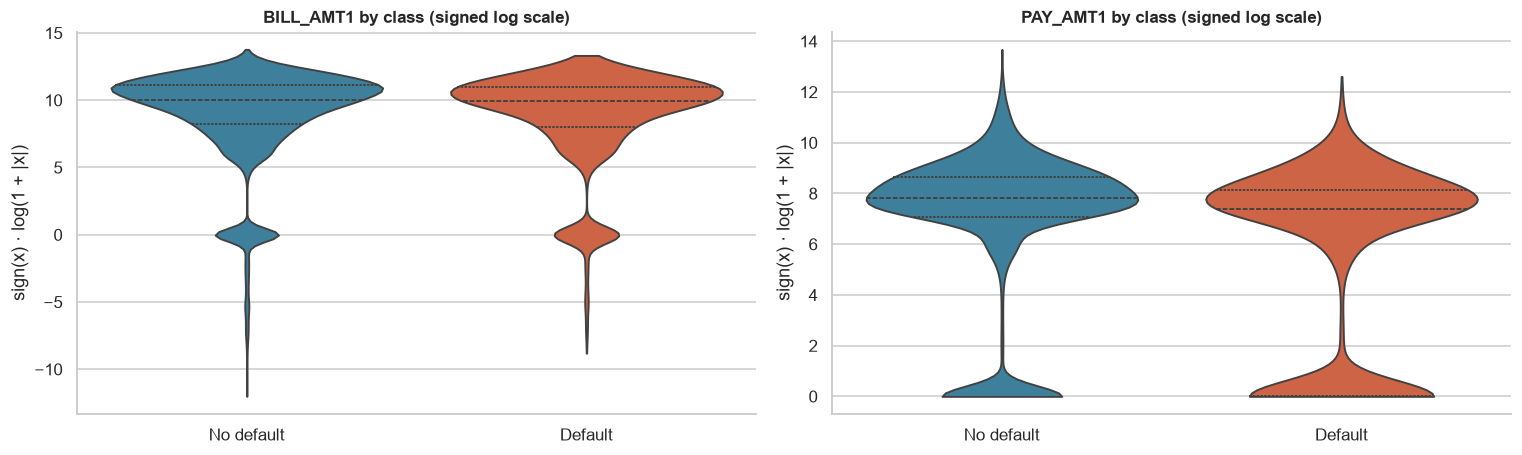

      BILL_AMT1: median no-default =   23,120 | median default =   20,185 | Mann-Whitney p = 1.2e-05 | univariate ROC-AUC = 0.518
       PAY_AMT1: median no-default =    2,460 | median default =    1,636 | Mann-Whitney p = 4.6e-170 | univariate ROC-AUC = 0.611
Default rate when nothing was paid in September: 35.9% (vs 19.2% otherwise)


In [21]:
class_names = df[TARGET].map(LABELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, col in zip(axes, ['BILL_AMT1', 'PAY_AMT1']):
    sns.violinplot(x=class_names, y=slog(df[col]), hue=class_names, legend=False, cut=0, inner='quartile',
                   order=[LABELS[0], LABELS[1]], hue_order=[LABELS[0], LABELS[1]],
                   palette={LABELS[k]: v for k, v in PALETTE.items()}, ax=ax)
    ax.set_title(f'{col} by class (signed log scale)')
    ax.set_xlabel('')
    ax.set_ylabel('sign(x) · log(1 + |x|)')
plt.tight_layout()
plt.show()

for col in BILL[:1] + PAY_AMT[:1]:
    compare_classes(col)
zero_pay = df.groupby(df['PAY_AMT1'] == 0)[TARGET].mean()
print(f'Default rate when nothing was paid in September: {zero_pay[True]:.1%} (vs {zero_pay[False]:.1%} otherwise)')

**H16 — rejected for bills; payments tell the story instead.**

- `BILL_AMT1` is almost the same in both classes (medians 23k vs 20k, ROC-AUC 0.52): **the amount owed does not predict default by itself.**
- `PAY_AMT1` separates the classes much better (ROC-AUC 0.61): defaulters pay less, and **35.9% of the clients who paid nothing in September defaulted, vs 19.2% of the others**.

What matters is not how much clients owe but **how much they repay relative to what they owe and to their limit**. This motivates the ratio features of section 6.

**Section 5 takeaways:** repayment status ≫ credit limit ≈ payment amounts ≫ demographics ≈ bill amounts. Several effects are non-monotonic (age, no-delay codes).

## 6. The time dimension

Each client has a 6-month history. A tabular classifier sees 18 separate columns; here we look at them as **trajectories**, which is where good engineered features come from.

### 6.1 Which bill does a payment pay?

**H17 — `PAY_AMTk` is the payment of the bill issued the month before (`BILL_AMT(k+1)`), not of the same month's bill.** This matters for any *repayment ratio* feature. If true, a payment should correlate more with the previous bill and match it exactly more often (clients who pay in full).

In [22]:
rows = []
for k in range(1, 6):
    pay, same, prev = df[f'PAY_AMT{k}'], df[f'BILL_AMT{k}'], df[f'BILL_AMT{k + 1}']
    rows.append({
        'payment': f'PAY_AMT{k} ({MONTHS[k - 1]})',
        'Spearman with same-month bill': pay.corr(same, method='spearman'),
        'Spearman with previous-month bill': pay.corr(prev, method='spearman'),
        '% paying exactly the same-month bill': 100 * ((pay == same) & (same > 0)).mean(),
        '% paying exactly the previous-month bill': 100 * ((pay == prev) & (prev > 0)).mean(),
    })
pd.DataFrame(rows).set_index('payment').round(3)

,Spearman with same-month bill,Spearman with previous-month bill,% paying exactly the same-month bill,% paying exactly the previous-month bill
payment,,,,
PAY_AMT1 (Sep),0.502,0.636,2.237,13.553
PAY_AMT2 (Aug),0.498,0.638,2.120,13.623
PAY_AMT3 (Jul),0.492,0.634,2.147,13.610
PAY_AMT4 (Jun),0.507,0.647,2.160,14.537
PAY_AMT5 (May),0.525,0.666,1.940,15.387


**H17 — confirmed.** Every month, a payment correlates better with the previous month's bill (ρ ≈ 0.64) than with the same month's bill (ρ ≈ 0.50), and it matches the previous bill **to the dollar** in 13–15% of the cases vs about 2% for the same month's bill. So `PAY_AMT1` (September) pays `BILL_AMT2` (August statement), and repayment ratios must be built as `PAY_AMTk / BILL_AMT(k+1)`.

### 6.2 Average trajectories by class

**Method.** Median bill, median payment and share of clients in delay, month by month, for each class. Medians rather than means, because of the heavy tails seen in 4.3.

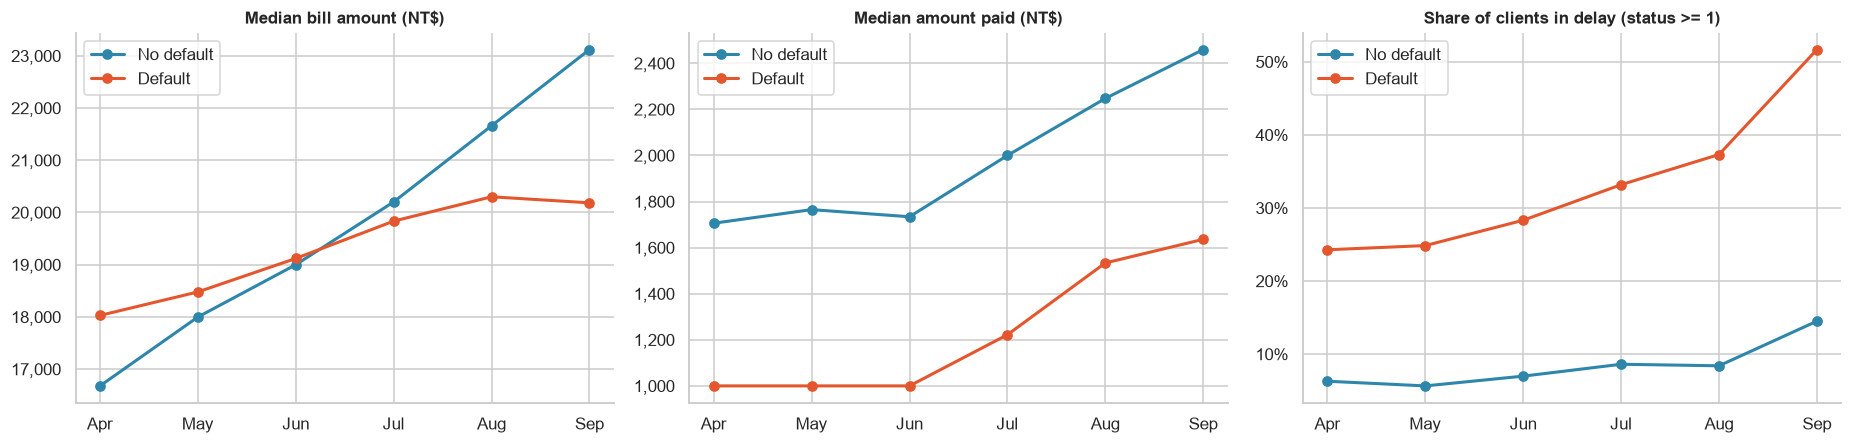

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for cls in (0, 1):
    sub = df[df[TARGET] == cls]
    style = dict(marker='o', color=PALETTE[cls], label=LABELS[cls], lw=2)
    axes[0].plot(CHRONO, sub[BILL].median().values[::-1], **style)
    axes[1].plot(CHRONO, sub[PAY_AMT].median().values[::-1], **style)
    axes[2].plot(CHRONO, (sub[PAY_STATUS] >= 1).mean().values[::-1], **style)
titles = ['Median bill amount (NT$)', 'Median amount paid (NT$)', 'Share of clients in delay (status >= 1)']
for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.legend()
for ax in axes[:2]:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
axes[2].yaxis.set_major_formatter(mticker.PercentFormatter(1))
plt.tight_layout()
plt.show()

**Result.** Three different stories:

- **Bills:** the median bill of non-defaulters grows steadily (16.7k → 23.1k), whereas that of defaulters stalls from July (about 20k). The two curves cross in June, which explains why the bill *level* is useless: it is the *dynamics* that differ.
- **Payments:** defaulters consistently pay less, a median of 1,000 NT$ from April to June against about 1,700 for non-defaulters, and the gap persists until September.
- **Delays:** the share of future defaulters in delay climbs from 24% in April to **52% in September**, while non-defaulters stay below 15%. The deterioration **accelerates over the last two months** before the default.

**For the classifier:** trends (slopes over the last months) and the most recent observations deserve dedicated features.

### 6.3 Behavioural features: a first look

**H18 — Ratios and behaviour summaries carry more signal than raw amounts.** A bill of 50,000 NT$ means something very different for a client with a 60,000 limit than for one with a 500,000 limit. Candidate features (not added to the dataset yet, this is still exploration):

| Feature | Definition |
|---|---|
| `UTILIZATION` | `BILL_AMT1 / LIMIT_BAL` — how much of the limit is used |
| `AVG_UTILIZATION` | mean of the 6 bills / `LIMIT_BAL` |
| `REPAY_RATIO` | `PAY_AMT1 / BILL_AMT2` — share of the previous bill actually repaid (uses H17) |
| `MONTHS_DELAYED` | number of months with status ≥ 1 |
| `MAX_DELAY` | worst status over the 6 months |
| `N_ZERO_PAYMENTS` | number of months with no payment |
| `BILL_TREND` | `(BILL_AMT1 − BILL_AMT6) / LIMIT_BAL` — is the debt growing? |

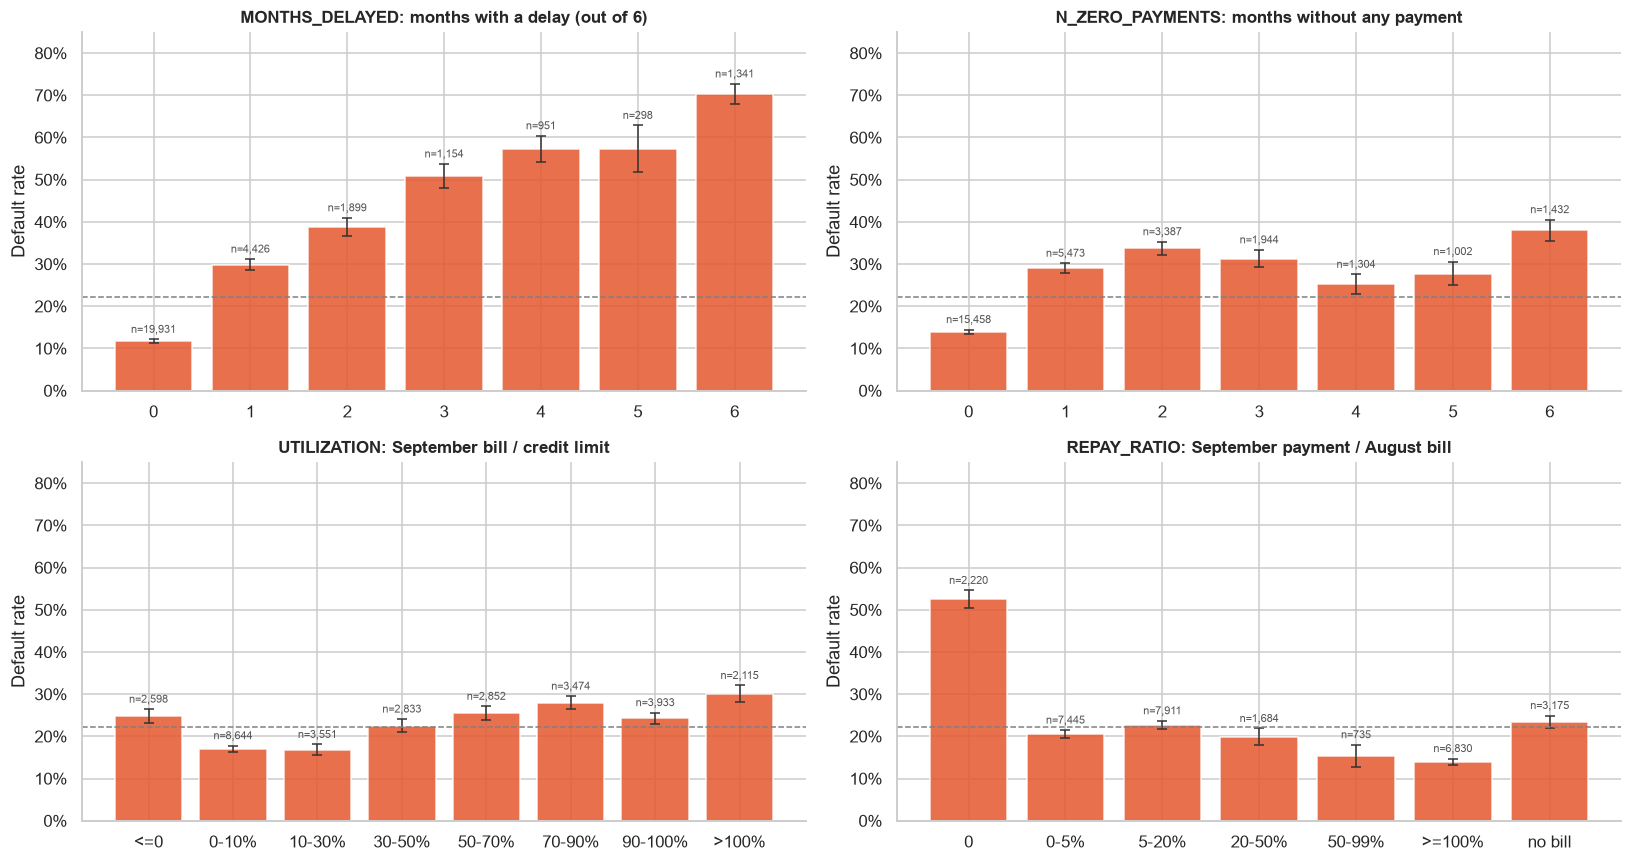

    UTILIZATION: median no-default =    0.267 | median default =    0.493 | Mann-Whitney p = 1.3e-36 | univariate ROC-AUC = 0.551
AVG_UTILIZATION: median no-default =    0.242 | median default =    0.463 | Mann-Whitney p = 4.4e-57 | univariate ROC-AUC = 0.564
 MONTHS_DELAYED: median no-default =    0.000 | median default =    1.000 | Mann-Whitney p = 0.0e+00 | univariate ROC-AUC = 0.726
      MAX_DELAY: median no-default =    0.000 | median default =    2.000 | Mann-Whitney p = 0.0e+00 | univariate ROC-AUC = 0.716
N_ZERO_PAYMENTS: median no-default =    0.000 | median default =    1.000 | Mann-Whitney p = 2.1e-256 | univariate ROC-AUC = 0.627
     BILL_TREND: median no-default =    0.011 | median default =    0.000 | Mann-Whitney p = 4.0e-43 | univariate ROC-AUC = 0.555


In [24]:
eng = pd.DataFrame(index=df.index)
eng['UTILIZATION'] = df['BILL_AMT1'] / df['LIMIT_BAL']
eng['AVG_UTILIZATION'] = df[BILL].mean(axis=1) / df['LIMIT_BAL']
eng['REPAY_RATIO'] = (df['PAY_AMT1'] / df['BILL_AMT2'].where(df['BILL_AMT2'] > 0)).clip(upper=2)
eng['MONTHS_DELAYED'] = (df[PAY_STATUS] >= 1).sum(axis=1)
eng['MAX_DELAY'] = df[PAY_STATUS].clip(lower=0).max(axis=1)
eng['N_ZERO_PAYMENTS'] = (df[PAY_AMT] == 0).sum(axis=1)
eng['BILL_TREND'] = (df['BILL_AMT1'] - df['BILL_AMT6']) / df['LIMIT_BAL']
ENG = list(eng.columns)
eng[TARGET] = df[TARGET]

util_bin = pd.cut(eng['UTILIZATION'], [-np.inf, 0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, np.inf],
                  labels=['<=0', '0-10%', '10-30%', '30-50%', '50-70%', '70-90%', '90-100%', '>100%'])
repay_bin = pd.cut(eng['REPAY_RATIO'], [-0.001, 0, 0.05, 0.2, 0.5, 0.999, np.inf],
                   labels=['0', '0-5%', '5-20%', '20-50%', '50-99%', '>=100%'])
repay_bin = repay_bin.cat.add_categories('no bill').fillna('no bill')

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_default_rate(eng, 'MONTHS_DELAYED', axes[0, 0], title='MONTHS_DELAYED: months with a delay (out of 6)')
plot_default_rate(eng, 'N_ZERO_PAYMENTS', axes[0, 1], title='N_ZERO_PAYMENTS: months without any payment')
plot_default_rate(eng.assign(UTIL_BIN=util_bin), 'UTIL_BIN', axes[1, 0], title='UTILIZATION: September bill / credit limit')
plot_default_rate(eng.assign(REPAY_BIN=repay_bin), 'REPAY_BIN', axes[1, 1], title='REPAY_RATIO: September payment / August bill')
for ax in axes.ravel():
    ax.set_ylim(0, 0.85)
plt.tight_layout()
plt.show()

for col in ['UTILIZATION', 'AVG_UTILIZATION', 'MONTHS_DELAYED', 'MAX_DELAY', 'N_ZERO_PAYMENTS', 'BILL_TREND']:
    compare_classes(col, data=eng)

**H18 — confirmed for behaviour summaries, nuanced for ratios.**

- `MONTHS_DELAYED` is the best single feature so far (ROC-AUC **0.726**, above `PAY_1` at 0.690): the default rate climbs steadily from 11.7% (no delay in 6 months) to **70.3%** (late every month). `MAX_DELAY` is close behind (0.716).
- `REPAY_RATIO` reveals a clear threshold: clients who repaid **nothing** of a positive bill default at **about 52%**, while any repayment, even under 5%, brings the rate back to about 20%, and full repayment to about 14%.
- `N_ZERO_PAYMENTS` is informative (ROC-AUC 0.63) but not monotonic: never skipping a payment is what matters most.
- `UTILIZATION` is weaker than expected (ROC-AUC 0.55) but has a sensible shape: 17% default at 0–30% usage, rising to **30% above the limit**. Defaulters use about half of their limit (median 0.49) vs a quarter for non-defaulters (0.27). The clients with a zero or negative bill default at 25%, an unexpected group investigated in section 10.3.

These features compress 6 columns into one meaningful number and will be built properly in the curation notebook.

### 6.4 How does the status evolve from one month to the next?

**Method.** A transition matrix: for every client and every pair of consecutive months (5 pairs × 30,000 clients), we count the move from status *s* to status *s′* and normalise each row. This is a first-order **Markov chain** view of the repayment behaviour.

**Consistency check.** A delay can only grow by one month per month. A jump such as 0 → 3 is impossible in real life; given the coding quirk found in H7 (first delay recorded as 2), we only flag transitions to a status ≥ 3 that jump more than one step.

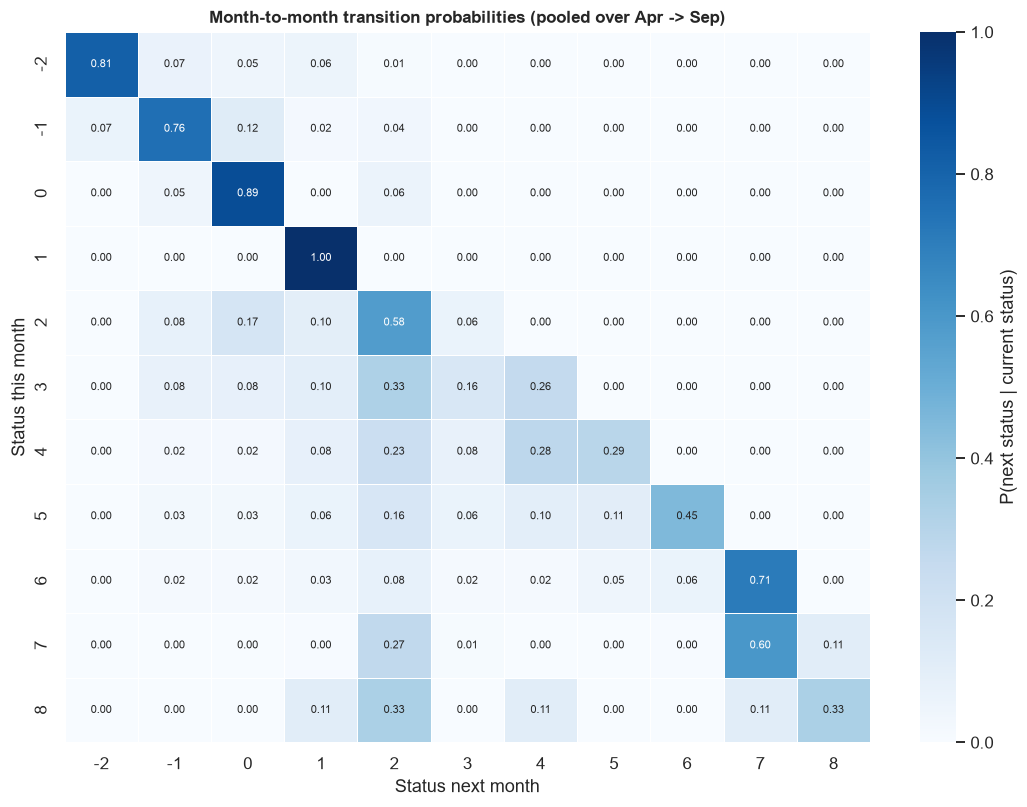

Impossible jumps (delay grows by more than one month): {'PAY_2 -> PAY_1': 0, 'PAY_3 -> PAY_2': 0, 'PAY_4 -> PAY_3': 0, 'PAY_5 -> PAY_4': 0, 'PAY_6 -> PAY_5': 0}
Total: 0 of 150,000 transitions (0.00%)


In [25]:
pairs = [(f'PAY_{k + 1}', f'PAY_{k}') for k in range(1, 6)]
transitions = sum(pd.crosstab(df[a], df[b]).reindex(index=STATUS_ORDER, columns=STATUS_ORDER, fill_value=0)
                  for a, b in pairs)
trans_prob = transitions.div(transitions.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(trans_prob, annot=True, fmt='.2f', cmap='Blues', linewidths=0.4, ax=ax, annot_kws={'fontsize': 7},
            cbar_kws={'label': 'P(next status | current status)'})
ax.set_xlabel('Status next month')
ax.set_ylabel('Status this month')
ax.set_title('Month-to-month transition probabilities (pooled over Apr -> Sep)')
plt.tight_layout()
plt.show()

jumps = pd.Series({f'{a} -> {b}': ((df[b] >= 3) & (df[b] > df[a].clip(lower=0) + 1)).sum() for a, b in pairs})
print('Impossible jumps (delay grows by more than one month):', jumps.to_dict())
print(f'Total: {jumps.sum():,} of {len(df) * len(pairs):,} transitions ({jumps.sum() / (len(df) * len(pairs)):.2%})')

**Result.**

- **Consistency check passed:** across 150,000 month-to-month transitions, a delay never grows by more than one month at a time. The statuses are internally coherent, which increases our trust in the PAY variables (apart from the status 1 coding of H7).
- The diagonal dominates: −2, −1 and 0 are **sticky** states (76–89% stay there), so the most recent status already summarises a lot of the history.
- Status 2 is sticky too (58% stay at 2) and only 6% move on to 3. A genuine unpaid 2-month delay should become 3 the next month, so *status 2* rather describes clients who are **chronically behind by a small amount**: they keep paying something but never catch up.
- From status 4 upwards, clients mostly move to the next level (4 → 5: 29%, 5 → 6: 45%, 6 → 7: 71%): the debt ages and recovery becomes rare.
- The status 1 row is based on only 34 transitions (status 1 is almost always in September, the last month) and should be ignored.

This Markov-chain view suggests extra features such as *number of transitions to a worse status* or *months since the last delay*.

**Section 6 takeaways:** payments settle the previous month's bill; defaulters show a visible deterioration over the last months; ratio and count features summarise the history efficiently; the statuses are internally consistent.

## 7. Multivariate structure

### 7.1 Correlations

**Method.** Spearman (rank) correlation, which is robust to the heavy tails and captures any monotonic relationship, not only linear ones.

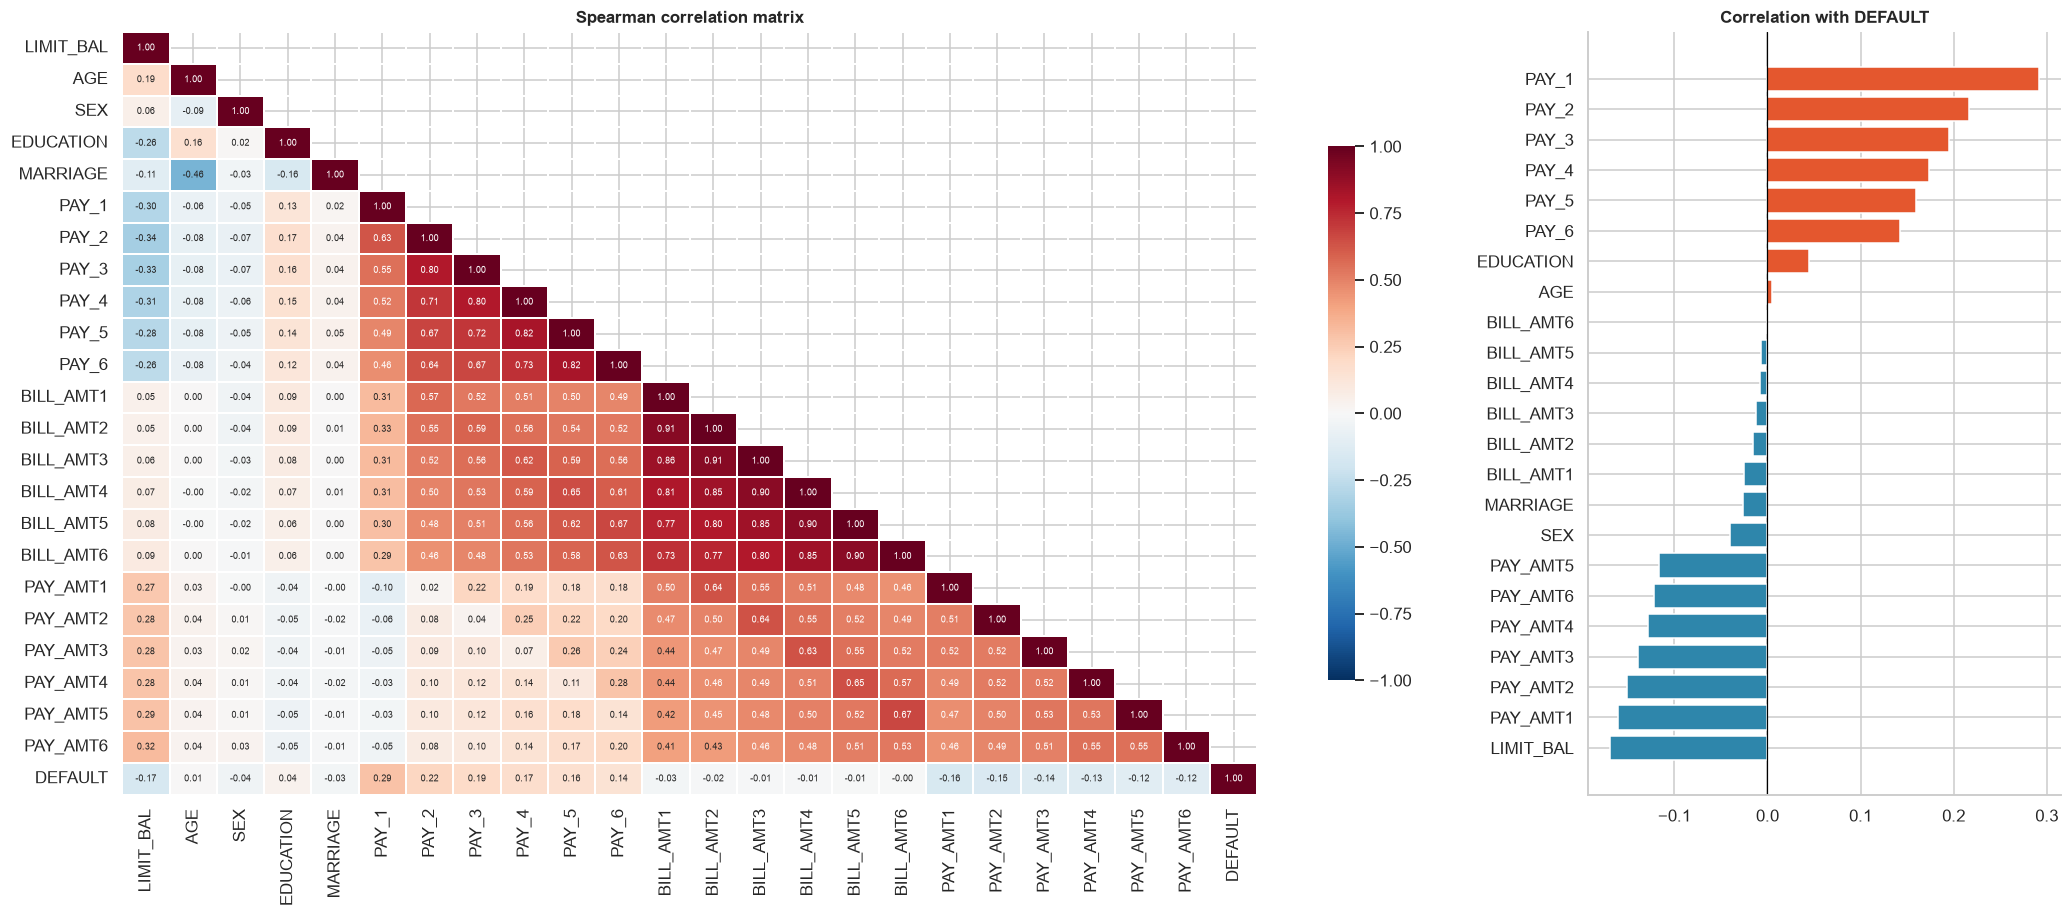

In [26]:
corr_cols = ['LIMIT_BAL', 'AGE', 'SEX', 'EDUCATION', 'MARRIAGE'] + PAY_STATUS + BILL + PAY_AMT + [TARGET]
corr = df[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5), gridspec_kw={'width_ratios': [3, 1]})
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'fontsize': 6}, linewidths=0.3, ax=axes[0], cbar_kws={'shrink': 0.7})
axes[0].set_title('Spearman correlation matrix')

target_corr = corr[TARGET].drop(TARGET).sort_values()
axes[1].barh(target_corr.index, target_corr.values, color=np.where(target_corr > 0, C_DEF, C_OK))
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Correlation with DEFAULT')
plt.tight_layout()
plt.show()

**Result.**

- Three **blocks** stand out: the six `BILL_AMT` (ρ = 0.73–0.95, highest between adjacent months), the six `PAY_k` (ρ ≈ 0.45–0.80) and, more loosely, the six `PAY_AMT` (ρ ≈ 0.4–0.6).
- `LIMIT_BAL` correlates positively with payments (ρ ≈ 0.3) and negatively with delays (ρ ≈ −0.3): clients with a high limit pay more and are late less often.
- `AGE` and `MARRIAGE` are correlated (ρ ≈ −0.48): older clients are more often married (code 1).
- Correlation with `DEFAULT`: positive for every `PAY_k`, decreasing from September (0.29) to April; negative for `LIMIT_BAL` (−0.17) and all `PAY_AMT`; **close to zero for every `BILL_AMT`**, as already seen in 5.5.

### 7.2 Multicollinearity

**H19 — The six bill amounts are largely redundant.**

**Method.** Variance Inflation Factor: VIF_j = 1 / (1 − R²_j), where R²_j is obtained by regressing feature *j* on all the others. It equals the diagonal of the inverse correlation matrix. Rule of thumb: VIF > 5 is worrying, VIF > 10 is severe (for linear models).

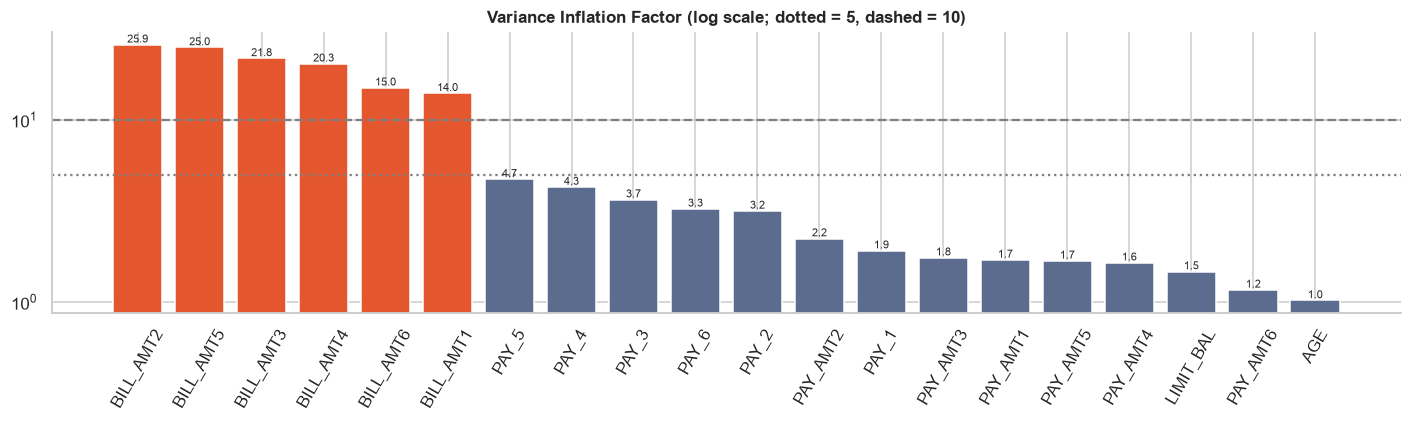

In [27]:
num_cols = ['LIMIT_BAL', 'AGE'] + PAY_STATUS + BILL + PAY_AMT
vif = pd.Series(np.diag(np.linalg.inv(df[num_cols].corr().values)), index=num_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(13, 4))
colors = np.where(vif > 10, C_DEF, np.where(vif > 5, '#F2A541', C_NEUTRAL))
bars = ax.bar(vif.index, vif.values, color=colors)
ax.bar_label(bars, labels=[f'{v:.1f}' for v in vif.values], fontsize=7)
ax.axhline(5, ls=':', color='grey')
ax.axhline(10, ls='--', color='grey')
ax.set_yscale('log')
ax.set_title('Variance Inflation Factor (log scale; dotted = 5, dashed = 10)')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

**H19 — confirmed.** The six bills have VIFs between 14 and 26: each bill is almost perfectly predicted by the other five. Every other variable stays below 5. For a logistic regression this inflates the variance of the coefficients and makes them unreadable; for trees it merely spreads the importance over six near-copies.

**Options for curation:** keep one or two bills (e.g. the latest) plus summaries (mean bill, bill trend, utilization), rely on L1/L2 regularisation, or replace the six bills by their first principal component.

### 7.3 Interactions

**H20 — The effect of a delay depends on the client's profile.** In particular, a delay should be more alarming for a client with a low credit limit (already considered risky by the bank).

**Method.** Default rate on two-way grids. If the effects simply added up, the rows of a grid would be parallel; diverging rows indicate an interaction that tree-based models capture natively but linear models would need explicit cross terms for.

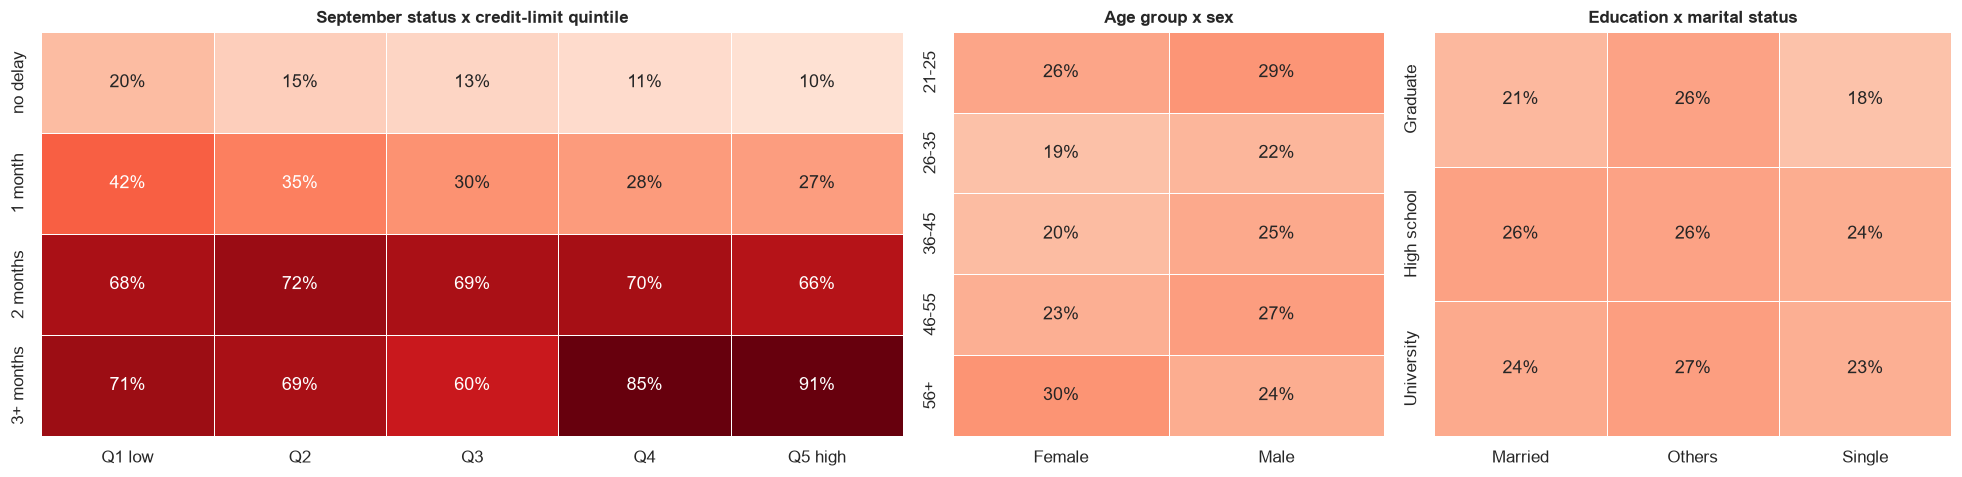

In [28]:
grid = df.assign(
    PAY_1_GROUP=pd.cut(df['PAY_1'], [-3, 0, 1, 2, 10], labels=['no delay', '1 month', '2 months', '3+ months']),
    LIMIT_Q=pd.qcut(df['LIMIT_BAL'], 5, labels=['Q1 low', 'Q2', 'Q3', 'Q4', 'Q5 high']),
    AGE_GROUP=pd.cut(df['AGE'], [20, 25, 35, 45, 55, 80], labels=['21-25', '26-35', '36-45', '46-55', '56+']),
    SEX_L=df['SEX'].map(SEX_LABELS),
    EDU_L=df['EDUCATION'].map(EDU_LABELS),
    MAR_L=df['MARRIAGE'].map(MAR_LABELS),
)
documented_rows = grid['EDUCATION'].between(1, 3) & grid['MARRIAGE'].between(1, 3)
specs = [
    (grid, 'PAY_1_GROUP', 'LIMIT_Q', 'September status x credit-limit quintile'),
    (grid, 'AGE_GROUP', 'SEX_L', 'Age group x sex'),
    (grid[documented_rows], 'EDU_L', 'MAR_L', 'Education x marital status'),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={'width_ratios': [5, 2.5, 3]})
for ax, (data, rows_, cols_, title) in zip(axes, specs):
    pivot = data.pivot_table(index=rows_, columns=cols_, values=TARGET, aggfunc='mean', observed=True)
    sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=0.8, linewidths=0.5, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

**H20 — nuanced.**

- For clients with **no delay** or **one month** of delay, the credit limit matters a lot: from the lowest to the highest quintile, 20% → 10% and 42% → 27%.
- With **two months** of delay the limit no longer matters (66–72% everywhere): the delay dominates.
- With **3+ months**, high-limit clients are the *riskiest* (85–91%), the opposite of H20. These cells are small, but the pattern makes sense: a large unpaid debt on a big limit is hard to recover.
- **Age × sex:** men are riskier in every age group *except* 56+, where women default more (30% vs 24%). A real interaction, but it concerns few clients.
- **Education × marital status:** no strong interaction; single graduates are the safest group (18%).

**Implication:** the effects are **not additive**. Random forests and gradient boosting capture such interactions natively; a logistic regression would need explicit interaction terms.

**Section 7 takeaways:** strong redundancy inside the bill block, moderate inside the status block; meaningful interactions between delay and credit limit.

## 8. Which features carry the signal?

We now rank all 23 original features **and** the 7 behavioural candidates of section 6.3 with three complementary, model-free measures:

| Measure | What it captures | Blind spot |
|---|---|---|
| **Univariate ROC-AUC** | how well the raw value *ranks* defaulters above non-defaulters | non-monotonic effects (e.g. the age U-shape) |
| **Mutual information** | any statistical dependence, monotonic or not | scale is hard to interpret |
| **Information Value (IV)** | credit-scoring standard, computed from Weight of Evidence on 10 quantile bins | depends on the binning |

IV rule of thumb used by credit scorers: < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, > 0.5 very strong (check for leakage).

This ranking is **univariate**: it says nothing about redundancy between features or about interactions. It guides the curation, it does not replace model-based importance.

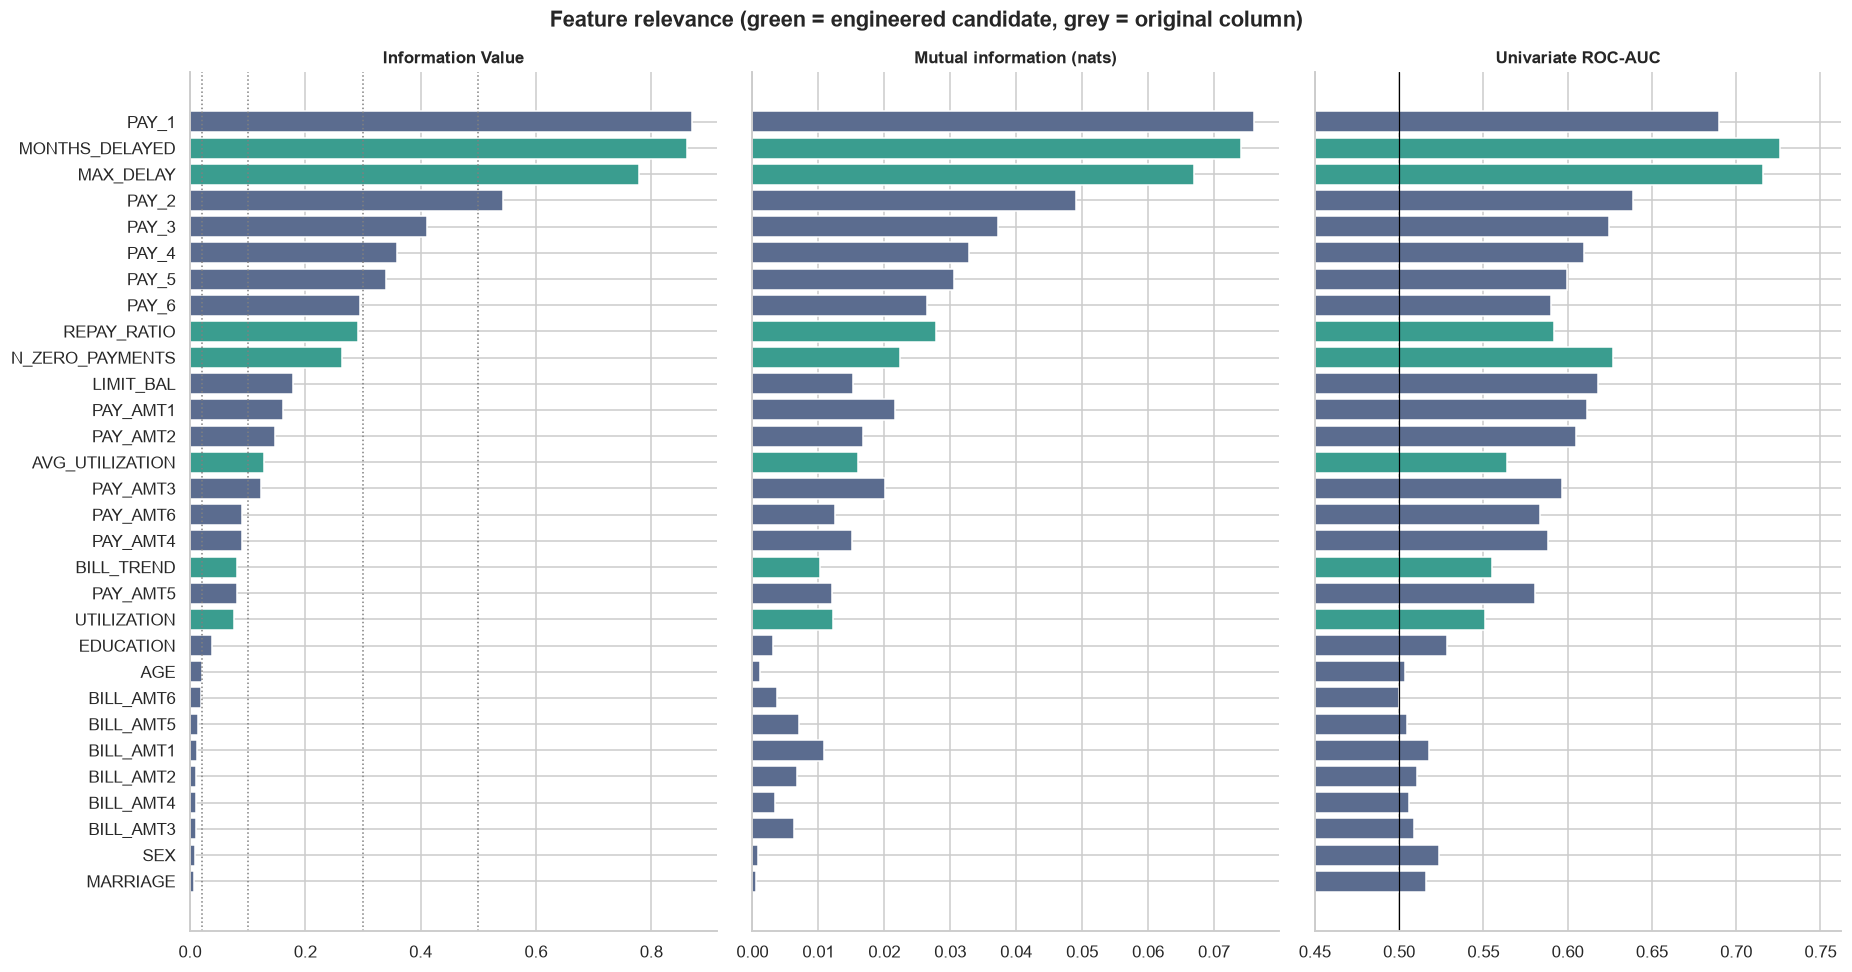

Rank agreement between the three measures (Spearman):
                   roc_auc  mutual_info  information_value
roc_auc               1.00         0.91               0.91
mutual_info           0.91         1.00               0.96
information_value     0.91         0.96               1.00


,roc_auc,mutual_info,information_value,engineered
PAY_1,0.690,0.076,0.870,False
MONTHS_DELAYED,0.726,0.074,0.862,True
MAX_DELAY,0.716,0.067,0.778,True
PAY_2,0.639,0.049,0.542,False
PAY_3,0.624,0.037,0.411,False
PAY_4,0.610,0.033,0.359,False
PAY_5,0.600,0.031,0.341,False
PAY_6,0.590,0.026,0.294,False
REPAY_RATIO,0.592,0.028,0.291,True
N_ZERO_PAYMENTS,0.627,0.022,0.263,True


In [29]:
def information_value(x, y, bins=10):
    x = pd.Series(x)
    if x.nunique() > bins:
        x = pd.qcut(x, bins, duplicates='drop')
    t = pd.crosstab(x.astype(str), y)
    dist_good = (t[0] + 0.5) / t[0].sum()
    dist_bad = (t[1] + 0.5) / t[1].sum()
    return float(((dist_bad - dist_good) * np.log(dist_bad / dist_good)).sum())


y = df[TARGET]
candidates = pd.concat([features, eng[ENG]], axis=1)
candidates_filled = candidates.fillna(-1)
discrete = DEMO_CAT + PAY_STATUS + ['MONTHS_DELAYED', 'MAX_DELAY', 'N_ZERO_PAYMENTS']

auc = candidates_filled.apply(lambda s: roc_auc_score(y, s))
mi = mutual_info_classif(candidates_filled, y, discrete_features=candidates.columns.isin(discrete).tolist(),
                         random_state=RANDOM_STATE)
relevance = pd.DataFrame({
    'roc_auc': np.maximum(auc, 1 - auc),
    'mutual_info': mi,
    'information_value': candidates.apply(lambda s: information_value(s, y)),
    'engineered': candidates.columns.isin(ENG),
}, index=candidates.columns).sort_values('information_value', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 9), sharey=True)
colors = np.where(relevance['engineered'], '#3A9D8F', C_NEUTRAL)
for ax, col, title in zip(axes, ['information_value', 'mutual_info', 'roc_auc'],
                          ['Information Value', 'Mutual information (nats)', 'Univariate ROC-AUC']):
    ax.barh(relevance.index[::-1], relevance[col][::-1], color=colors[::-1])
    ax.set_title(title)
for v in (0.02, 0.1, 0.3, 0.5):
    axes[0].axvline(v, ls=':', color='grey', lw=1)
axes[2].set_xlim(0.45, None)
axes[2].axvline(0.5, color='black', lw=0.8)
fig.suptitle('Feature relevance (green = engineered candidate, grey = original column)', fontweight='bold')
plt.tight_layout()
plt.show()

print('Rank agreement between the three measures (Spearman):')
print(relevance[['roc_auc', 'mutual_info', 'information_value']].corr(method='spearman').round(2))
relevance.round(3)

**Result.**

- The three measures **agree** (rank correlations 0.91–0.96), so the ranking is robust to the choice of measure.
- **Repayment behaviour dominates:** `PAY_1` (IV 0.87), `MONTHS_DELAYED` (0.86) and `MAX_DELAY` (0.78) are *very strong*, followed by `PAY_2` (0.54) and `PAY_3`–`PAY_6`, `REPAY_RATIO` and `N_ZERO_PAYMENTS` (0.26–0.41, strong to medium).
- `LIMIT_BAL` and the payment amounts come next (0.08–0.18, weak to medium).
- **Raw bill amounts, sex, marital status and age are almost useless on their own** (IV ≤ 0.02); education is weak (0.04). Age is under-rated here because its effect is U-shaped and these measures are computed on coarse bins or ranks.
- **Feature engineering pays off:** `MONTHS_DELAYED` and `MAX_DELAY` rival `PAY_1` while summarising 6 columns, and the three bill-based ratios (`AVG_UTILIZATION`, `BILL_TREND`, `UTILIZATION`, IV 0.08–0.13) carry 4 to 7 times more information than the best raw bill (IV ≤ 0.02).
- A very high IV normally triggers a **leakage** check. Here it is fine: `PAY_1` describes September and the target describes October, so no information comes from the future.

## 9. Geometry of the classes

**H21 — In the full feature space, defaulters and non-defaulters form well-separated groups.** If true, almost any classifier would do very well; if false, we should expect a performance ceiling whatever the model.

**Method.** Monetary variables are signed-log transformed, everything is standardised, then:
1. **PCA**: how many linear directions are needed to describe the data, and do the classes separate along the main ones?
2. **t-SNE** (on a stratified sample of 4,000 clients, for speed): a non-linear projection that preserves local neighbourhoods.
3. **k-nearest-neighbour purity**: for each client, the share of its 15 nearest neighbours that defaulted. If classes were separated, defaulters would be surrounded by defaulters.

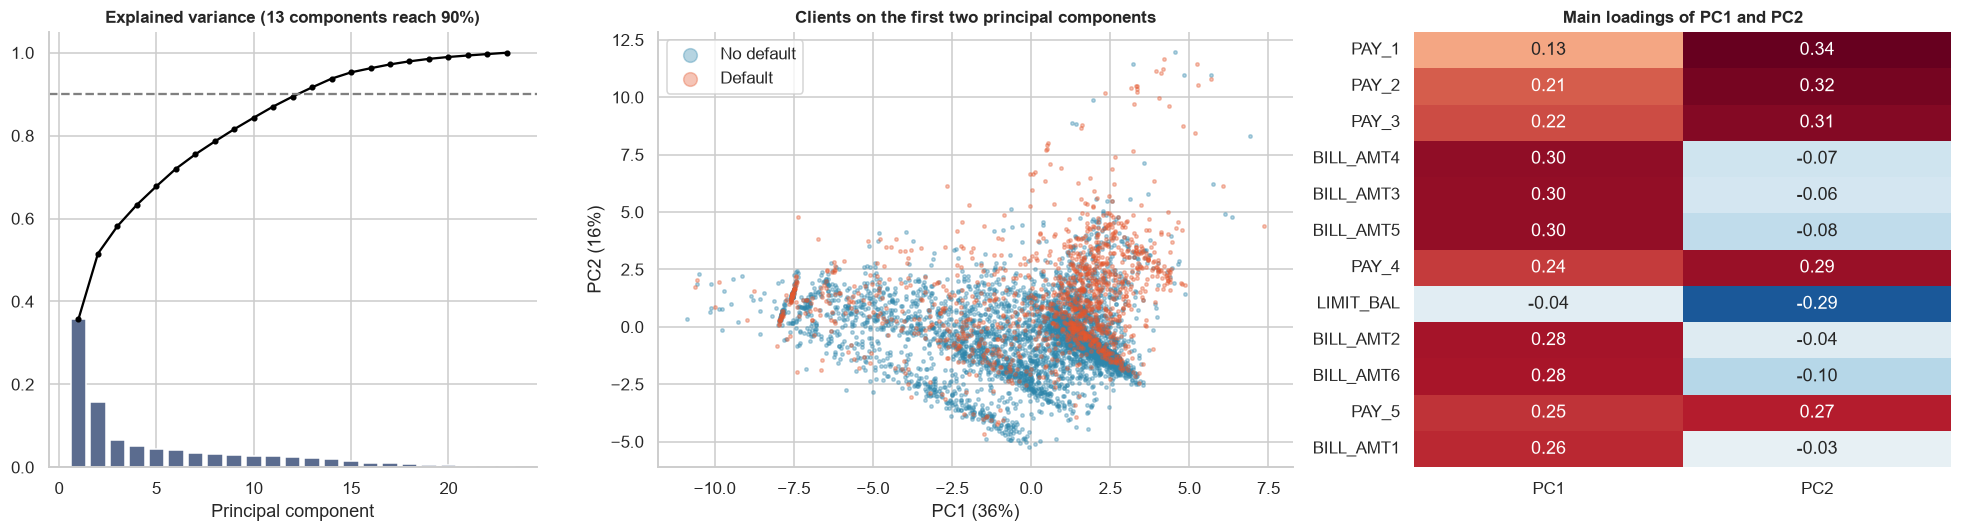

PC1 of clients whose 6 bills are all 0: median -7.6, range [-8.0, -6.9]  (all clients: median 1.1)
Share of clients with PC1 < -6 whose 6 bills are all 0: 45%


In [30]:
X_geo = features.astype(float).copy()
X_geo[money] = slog(X_geo[money])
X_std = StandardScaler().fit_transform(X_geo)

pca = PCA(random_state=RANDOM_STATE).fit(X_std)
Z = pca.transform(X_std)
cum_var = np.cumsum(pca.explained_variance_ratio_)

rng = np.random.default_rng(RANDOM_STATE)
show = rng.choice(len(df), 6000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.3, 1.1]})
axes[0].bar(range(1, len(cum_var) + 1), pca.explained_variance_ratio_, color=C_NEUTRAL)
axes[0].plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='black', ms=3)
axes[0].axhline(0.9, ls='--', color='grey')
axes[0].set_title(f'Explained variance ({np.argmax(cum_var >= 0.9) + 1} components reach 90%)')
axes[0].set_xlabel('Principal component')

for cls in (0, 1):
    idx = show[df[TARGET].values[show] == cls]
    axes[1].scatter(Z[idx, 0], Z[idx, 1], s=5, alpha=0.35, color=PALETTE[cls], label=LABELS[cls])
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
axes[1].legend(markerscale=4)
axes[1].set_title('Clients on the first two principal components')

loadings = pd.DataFrame(pca.components_[:2].T, index=features.columns, columns=['PC1', 'PC2'])
top = loadings.abs().max(axis=1).sort_values(ascending=False).index[:12]
sns.heatmap(loadings.loc[top], annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[2], cbar=False)
axes[2].set_title('Main loadings of PC1 and PC2')
plt.tight_layout()
plt.show()

no_bill = (df[BILL] == 0).all(axis=1).to_numpy()
print(f'PC1 of clients whose 6 bills are all 0: median {np.median(Z[no_bill, 0]):.1f}, '
      f'range [{Z[no_bill, 0].min():.1f}, {Z[no_bill, 0].max():.1f}]  (all clients: median {np.median(Z[:, 0]):.1f})')
print(f'Share of clients with PC1 < -6 whose 6 bills are all 0: {no_bill[Z[:, 0] < -6].mean():.0%}')

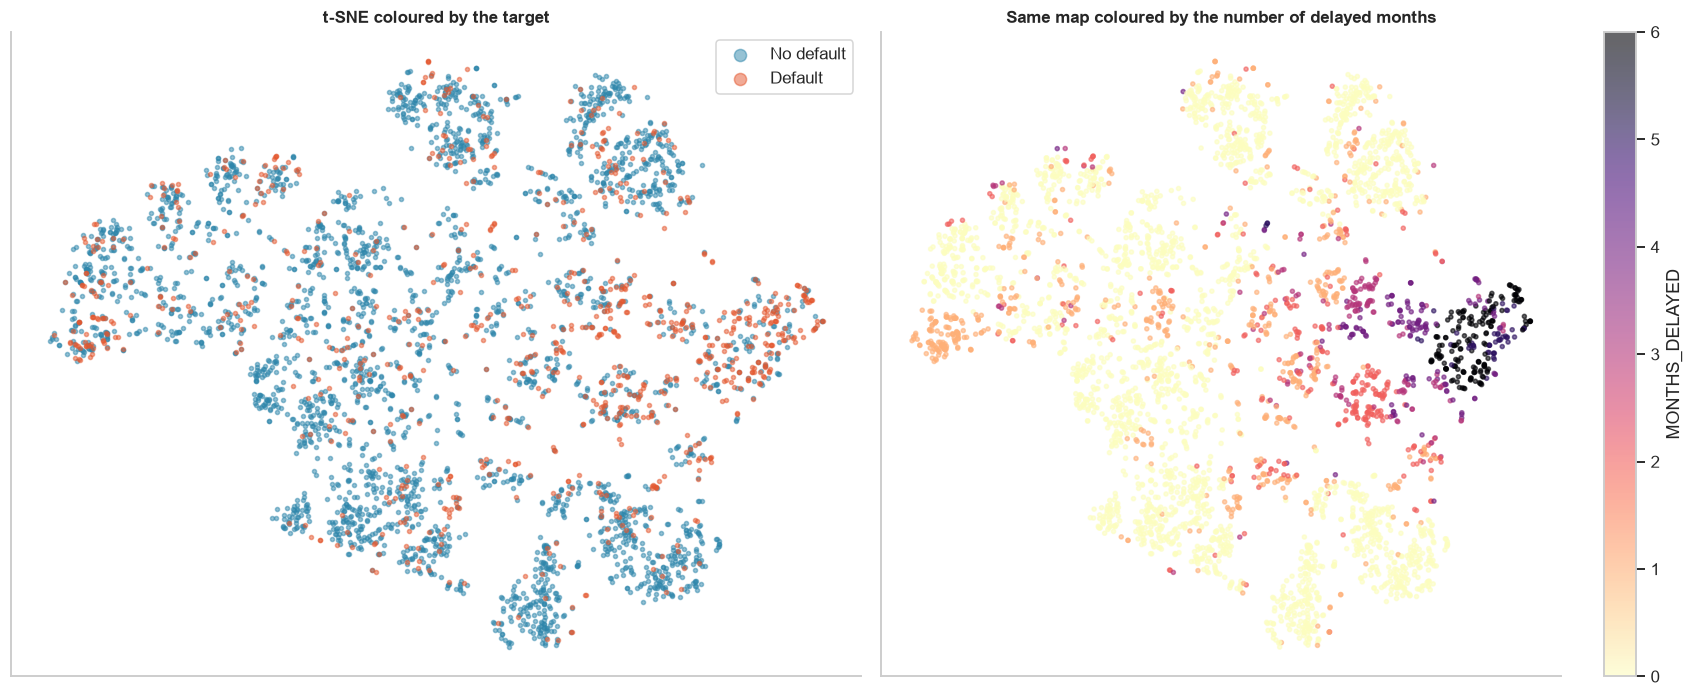

Average share of defaulters among the 15 nearest neighbours of a defaulter:     36.7%
Average share of defaulters among the 15 nearest neighbours of a non-defaulter: 17.3%
Overall default rate (what a random neighbourhood would give):                  22.1%


In [31]:
sample_idx = (df.groupby(TARGET, group_keys=False)
                .sample(frac=4000 / len(df), random_state=RANDOM_STATE).index.to_numpy())
emb = TSNE(n_components=2, perplexity=40, init='pca', random_state=RANDOM_STATE).fit_transform(X_std[sample_idx])
y_sample = df[TARGET].values[sample_idx]
months_delayed_sample = eng['MONTHS_DELAYED'].values[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for cls in (0, 1):
    axes[0].scatter(emb[y_sample == cls, 0], emb[y_sample == cls, 1], s=7, alpha=0.5,
                    color=PALETTE[cls], label=LABELS[cls])
axes[0].legend(markerscale=3)
axes[0].set_title('t-SNE coloured by the target')
sc = axes[1].scatter(emb[:, 0], emb[:, 1], s=7, alpha=0.6, c=months_delayed_sample, cmap='magma_r')
fig.colorbar(sc, ax=axes[1], label='MONTHS_DELAYED')
axes[1].set_title('Same map coloured by the number of delayed months')
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

knn_idx = rng.choice(len(df), 10_000, replace=False)
nn = NearestNeighbors(n_neighbors=16).fit(X_std[knn_idx])
_, neigh = nn.kneighbors(X_std[knn_idx])
y_knn = df[TARGET].values[knn_idx]
share_default_neigh = y_knn[neigh[:, 1:]].mean(axis=1)
print(f'Average share of defaulters among the 15 nearest neighbours of a defaulter:     {share_default_neigh[y_knn == 1].mean():.1%}')
print(f'Average share of defaulters among the 15 nearest neighbours of a non-defaulter: {share_default_neigh[y_knn == 0].mean():.1%}')
print(f'Overall default rate (what a random neighbourhood would give):                  {BASE_RATE:.1%}')

**H21 — rejected.**

- **PCA:** the first component (36% of the variance) is mainly an *activity* axis (bills and statuses), the second (16%) opposes delays to the credit limit. 13 components are needed to reach 90% of the variance, so the data is not low-dimensional. On the PC1–PC2 plane, defaulters gather in the upper region (delays, low limit) but are mixed with non-defaulters everywhere. The isolated stripe on the left (PC1 ≈ −7.6) is made of the clients whose six bills are all zero, as checked above.
- **t-SNE** finds many small local clusters (client *profiles*). Defaulters concentrate in the region on the right, which the second map identifies as the clients with many months of delay, but they are also scattered in almost every other cluster.
- **k-NN purity:** on average a defaulter's 15 nearest neighbours contain **36.7% defaulters**, against 22.1% for a random neighbourhood and 17.3% around a non-defaulter. There is real local signal, but **most neighbours of a defaulter are good payers**.

**Implication:** part of what causes a default is simply not in these 23 variables (job loss, illness, debts at other banks… are not recorded). We should expect a **performance ceiling**: published results on this dataset typically reach a ROC-AUC of about 0.77–0.79. In the modelling notebook, gains will come from good features, a tuned decision threshold and a robust validation more than from an exotic algorithm.

## 10. Outliers and anomalies

The next notebook has to decide what to do with outliers. Before removing anything, we need to know **what the outliers are** and **whether they are informative about default**.

### 10.1 Univariate outliers (Tukey's IQR rule)

**H22 — Points outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR] are errors that should be removed.**

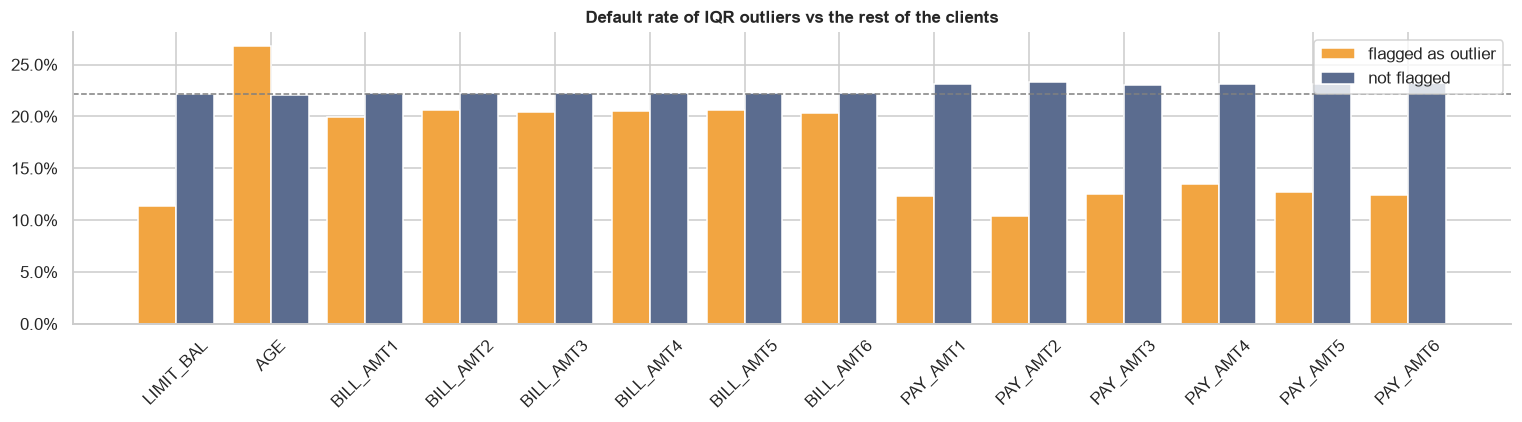

Clients flagged on at least one feature: 10,452 (34.8%), default rate 15.2%


,% flagged,default rate if flagged,default rate otherwise,upper fence,max
feature,,,,,
LIMIT_BAL,0.557,0.114,0.222,525000.000,1000000
AGE,0.907,0.268,0.221,60.500,79
BILL_AMT1,8.000,0.199,0.223,162389.375,964511
BILL_AMT2,7.983,0.206,0.223,155538.500,983931
BILL_AMT3,8.230,0.204,0.223,146412.500,1664089
BILL_AMT4,8.740,0.205,0.223,132774.875,891586
BILL_AMT5,9.083,0.206,0.223,122831.750,927171
BILL_AMT6,8.977,0.203,0.223,121111.625,961664
PAY_AMT1,9.150,0.123,0.231,11015.000,873552


In [32]:
rows = []
any_flag = pd.Series(False, index=df.index)
for col in ['LIMIT_BAL', 'AGE'] + BILL + PAY_AMT:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    flag = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    any_flag |= flag
    rows.append({'feature': col, '% flagged': 100 * flag.mean(),
                 'default rate if flagged': df.loc[flag, TARGET].mean(),
                 'default rate otherwise': df.loc[~flag, TARGET].mean(),
                 'upper fence': q3 + 1.5 * iqr, 'max': df[col].max()})
iqr_table = pd.DataFrame(rows).set_index('feature').round(3)

fig, ax = plt.subplots(figsize=(14, 4))
x = np.arange(len(iqr_table))
ax.bar(x - 0.2, iqr_table['default rate if flagged'], width=0.4, color='#F2A541', label='flagged as outlier')
ax.bar(x + 0.2, iqr_table['default rate otherwise'], width=0.4, color=C_NEUTRAL, label='not flagged')
ax.axhline(BASE_RATE, ls='--', color='grey', lw=1)
ax.set_xticks(x, iqr_table.index, rotation=45)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_title('Default rate of IQR outliers vs the rest of the clients')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Clients flagged on at least one feature: {any_flag.sum():,} ({any_flag.mean():.1%}), '
      f'default rate {df.loc[any_flag, TARGET].mean():.1%}')
iqr_table

**H22 — rejected.**

- The IQR rule flags 8–10% of the clients on **each** bill and payment column, and **34.8% of all clients on at least one feature**. Removing them would throw away a third of the data.
- These outliers are **not random noise**: payment and limit outliers default **much less** (10–13% vs 22–23%). They are wealthy clients who pay large amounts. Age outliers (over 60) default more (27%). Removing them would bias the sample and make the model over-estimate the risk of wealthy clients.
- The maxima are large but not implausible for credit cards, and no impossible value was found.

**Decision for curation:** keep these points. Handle the heavy tails with a transformation (signed log) or mild winsorisation (e.g. at the 99.5th percentile) for scale-sensitive models (logistic regression, SVM, k-NN, neural networks); leave them untouched for tree-based models.

### 10.2 Multivariate anomalies (Isolation Forest)

A client can look normal on every single variable and still be unusual as a whole (e.g. a huge bill with a tiny limit). **Isolation Forest** isolates points with random splits: anomalies need few splits to be isolated. We flag the 1% most anomalous clients in the standardised space of section 9 and look at who they are.

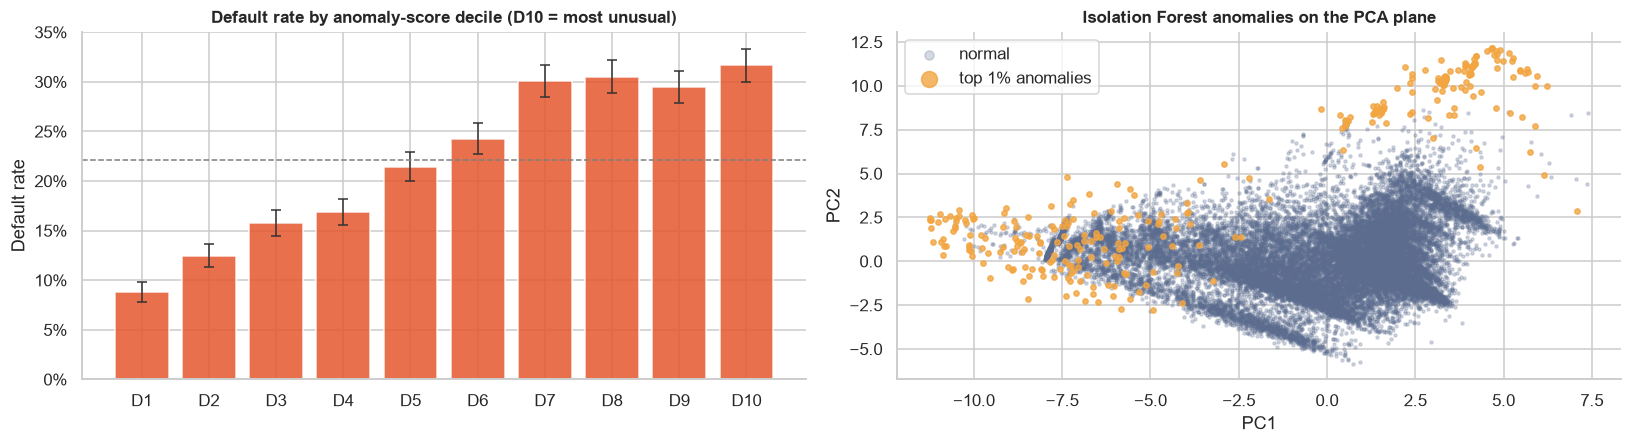

,top 1% anomalies (median),all clients (median),top 1% anomalies (mean),all clients (mean)
LIMIT_BAL,100000.0,140000.0,148366.67,167484.32
AGE,35.0,34.0,37.07,35.49
PAY_1,1.0,0.0,1.42,-0.02
BILL_AMT1,1361.0,22381.5,23942.33,51223.33
PAY_AMT1,0.0,2100.0,737.25,5663.58
PAY_AMT2,0.0,2009.0,2014.90,5921.16
DEFAULT,0.0,0.0,0.45,0.22


In [33]:
iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE).fit(X_std)
anomaly_score = -iso.score_samples(X_std)
iso_flag = iso.predict(X_std) == -1

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
score_decile = pd.qcut(anomaly_score, 10, labels=[f'D{i}' for i in range(1, 11)])
plot_default_rate(df.assign(SCORE_DECILE=score_decile), 'SCORE_DECILE', axes[0], show_n=False,
                  title='Default rate by anomaly-score decile (D10 = most unusual)')
for flag, color, label in [(False, C_NEUTRAL, 'normal'), (True, '#F2A541', 'top 1% anomalies')]:
    m = iso_flag == flag
    axes[1].scatter(Z[m, 0], Z[m, 1], s=4 if not flag else 12, alpha=0.25 if not flag else 0.8, color=color, label=label)
axes[1].legend(markerscale=3)
axes[1].set_title('Isolation Forest anomalies on the PCA plane')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
plt.tight_layout()
plt.show()

profile_cols = ['LIMIT_BAL', 'AGE', 'PAY_1', 'BILL_AMT1', 'PAY_AMT1', 'PAY_AMT2', TARGET]
pd.DataFrame({'top 1% anomalies (median)': df.loc[iso_flag, profile_cols].median(),
              'all clients (median)': df[profile_cols].median(),
              'top 1% anomalies (mean)': df.loc[iso_flag, profile_cols].mean(),
              'all clients (mean)': df[profile_cols].mean()}).round(2)

**Result.** The anomaly score is **strongly related to default**: the default rate rises from 9% in the most *normal* decile to 32% in the most unusual one, and the top 1% anomalies default at **45%**, twice the base rate. Their typical profile: a lower limit, a delay in September (median `PAY_1` = 1), small bills and **no payment** over the last two months. On the PCA plane they sit at the edges, in particular in the high-delay cloud at the top.

**Implication:** multivariate anomalies are not errors to delete; they are **at-risk clients**. Removing them would delete precisely the cases we want to detect. The anomaly score itself could even be tested as a feature.

### 10.3 Business-rule anomalies

Statistical rarity is not the same as *impossibility*. We finally check the records against simple business rules and measure how often each situation happens and how risky it is.

In [34]:
delay_jump = pd.concat([(df[b] >= 3) & (df[b] > df[a].clip(lower=0) + 1) for a, b in pairs], axis=1).any(axis=1)
rules = {
    'Duplicated row (ignoring ID)': df.drop(columns='ID').duplicated(keep=False),
    'Undocumented EDUCATION (0, 5, 6)': df['EDUCATION'].isin([0, 5, 6]),
    'Undocumented MARRIAGE (0)': df['MARRIAGE'].eq(0),
    'At least one negative bill': (df[BILL] < 0).any(axis=1),
    'September bill above credit limit': df['BILL_AMT1'] > df['LIMIT_BAL'],
    'September payment above August bill': (df['PAY_AMT1'] > df['BILL_AMT2']) & (df['BILL_AMT2'] > 0),
    'No activity at all (6 bills and 6 payments = 0)': (df[BILL + PAY_AMT] == 0).all(axis=1),
    'Delay jumps by more than one month': delay_jump,
}
rule_table = pd.DataFrame({
    'clients': {k: int(m.sum()) for k, m in rules.items()},
    '% of clients': {k: round(100 * m.mean(), 2) for k, m in rules.items()},
    'default rate': {k: round(df.loc[m, TARGET].mean(), 3) for k, m in rules.items()},
})
rule_table

,clients,% of clients,default rate
Duplicated row (ignoring ID),70,0.23,0.171
"Undocumented EDUCATION (0, 5, 6)",345,1.15,0.075
Undocumented MARRIAGE (0),54,0.18,0.093
At least one negative bill,1930,6.43,0.165
September bill above credit limit,2115,7.05,0.301
September payment above August bill,2757,9.19,0.104
No activity at all (6 bills and 6 payments = 0),795,2.65,0.376
Delay jumps by more than one month,0,0.00,NaN


**Result.** Each rule points to a curation decision:

| Situation | Clients | Default rate | Interpretation | Action in notebook 2 |
|---|---|---|---|---|
| Duplicated rows | 70 (35 copies) | 17% | copies, or identical simple profiles | drop exact duplicates |
| Undocumented `EDUCATION` / `MARRIAGE` | 345 / 54 | 7.5% / 9% | unknown codes, low risk | merge into *others* |
| Negative bill | 1,930 | 16.5% | credit balance in the client's favour | keep, signed log |
| Bill above the credit limit | 2,115 | **30%** | over-limit usage: allowed but risky | keep, utilization feature |
| Payment above the previous bill | 2,757 | 10% | client pays more than due | keep, clip the repayment ratio |
| **No activity at all** | **795** | **38%** | **suspicious**: no bill, no payment, yet one of the riskiest groups | investigate; at least add an `INACTIVE` flag |
| Delay growing by more than one month | 0 | — | statuses are coherent | nothing to do |

The *no activity* group is the main open question of the dataset. A client with no debt cannot default on a payment in the usual sense; possible explanations are accounts closed or frozen by the bank, debt held on another product of the same bank, or a labelling artefact. The group can be identified exactly, so a model can learn it, but the curation step must not treat these rows as noise.

## 11. Executive dashboard

One page that summarises the study, for a presentation or a report. It is also saved to `figures/01_eda_dashboard.png`.

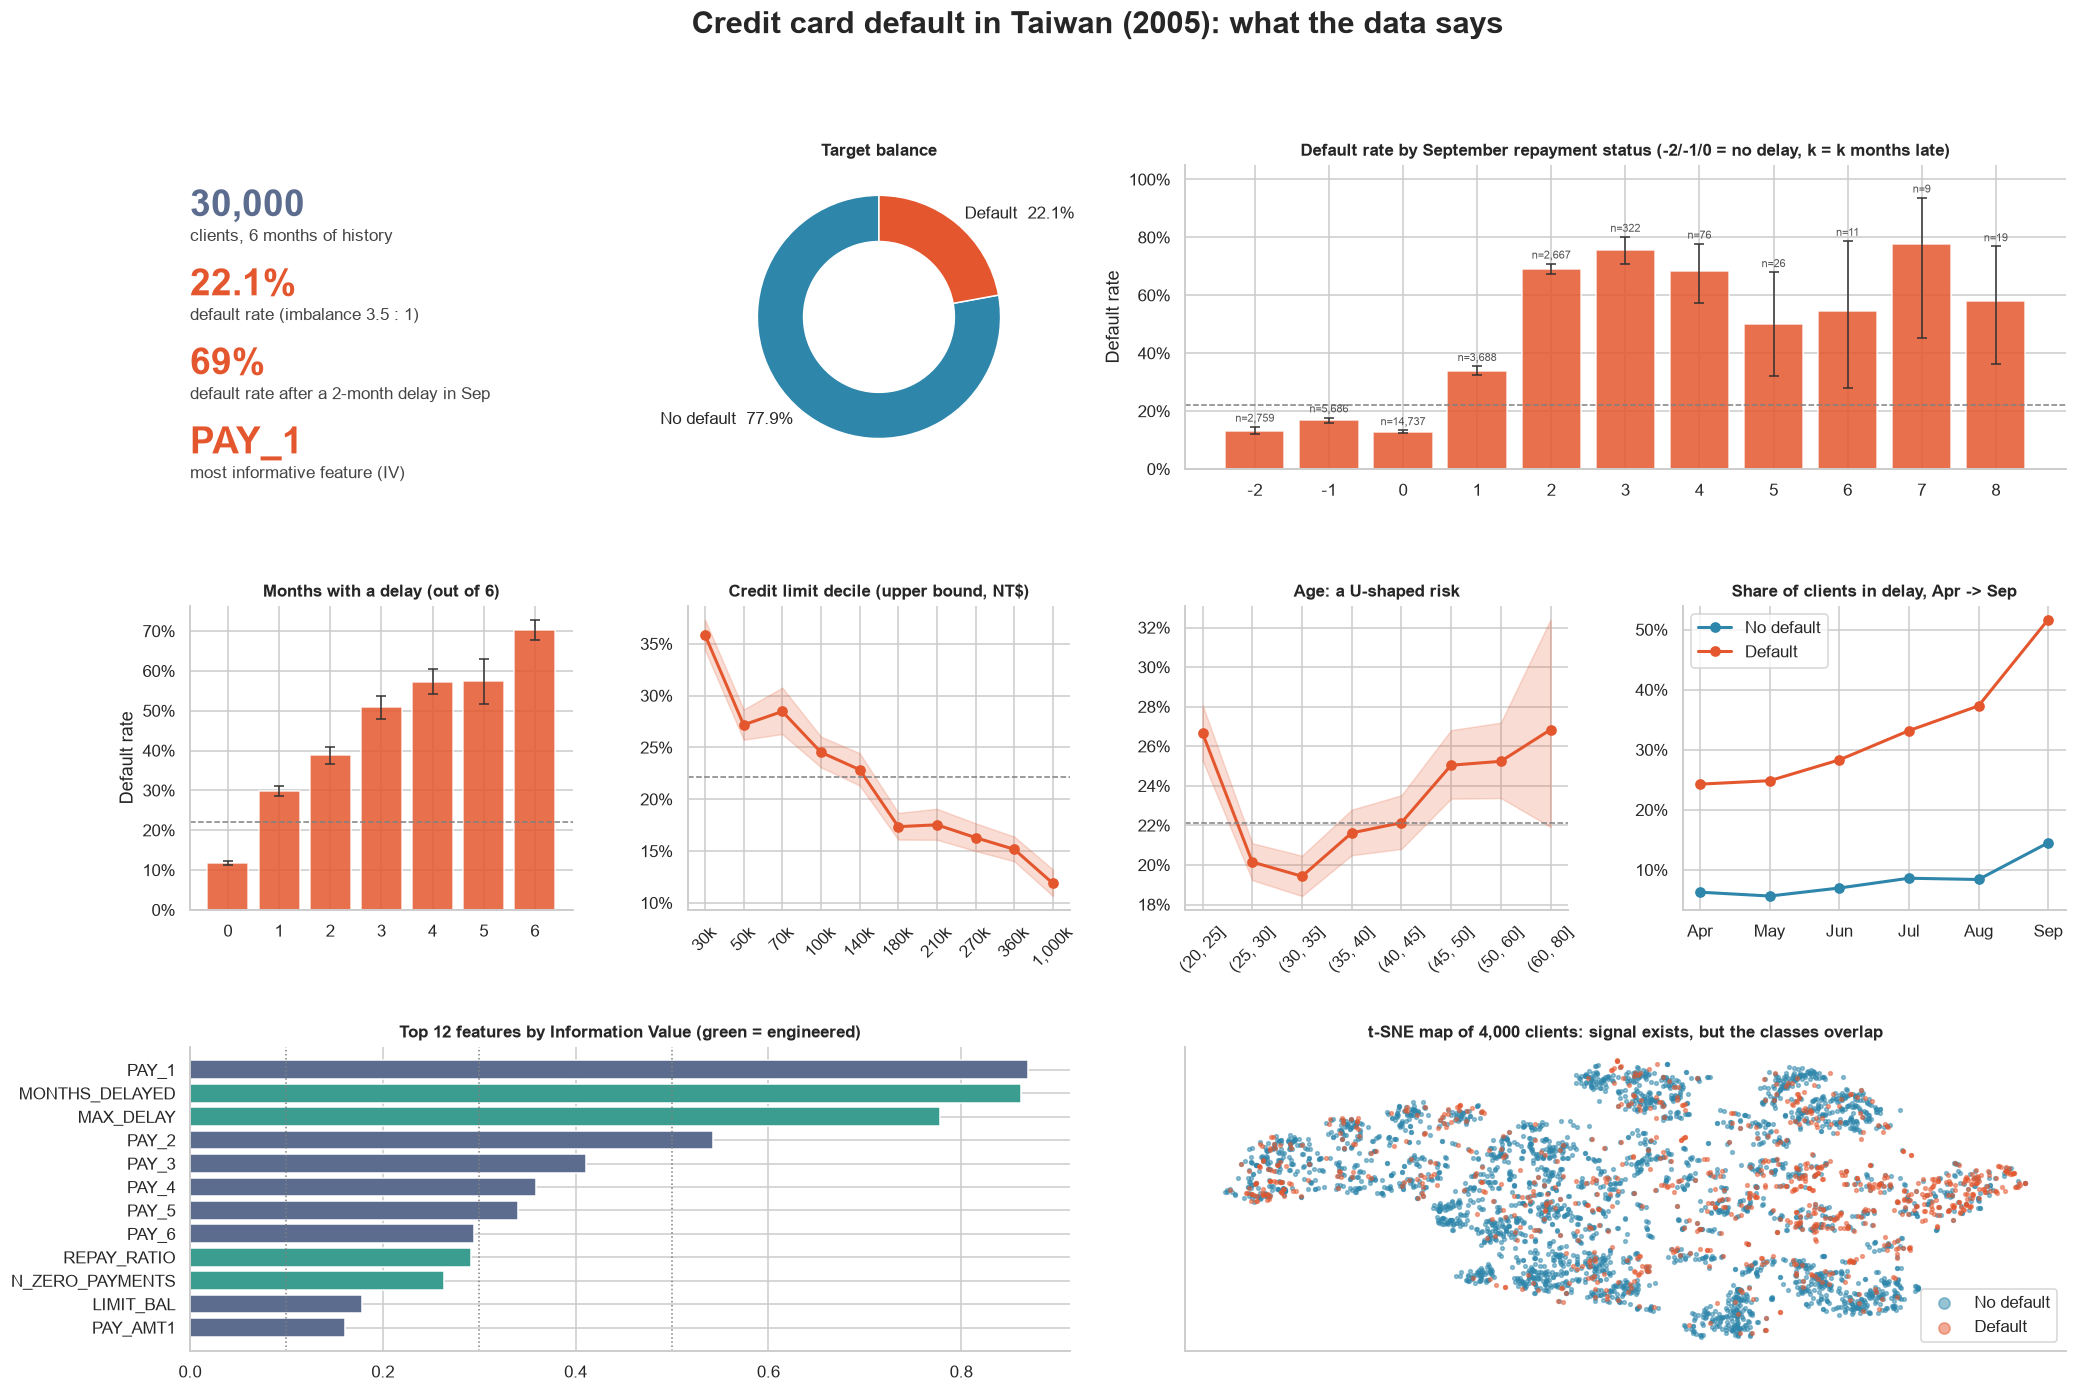

In [35]:
fig = plt.figure(figsize=(22, 14))
gs = GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.3)
fig.suptitle('Credit card default in Taiwan (2005): what the data says', fontsize=20, fontweight='bold', y=0.98)

# KPIs
ax = fig.add_subplot(gs[0, 0])
ax.axis('off')
kpis = [(f'{len(df):,}', 'clients, 6 months of history'),
        (f'{BASE_RATE:.1%}', 'default rate (imbalance 3.5 : 1)'),
        (f'{default_rate(df, "PAY_1").loc[2, "rate"]:.0%}', 'default rate after a 2-month delay in Sep'),
        (f'{relevance.index[0]}', 'most informative feature (IV)')]
for i, (value, label) in enumerate(kpis):
    ax.text(0.0, 0.92 - i * 0.26, value, fontsize=24, fontweight='bold', color=C_DEF if i else C_NEUTRAL,
            transform=ax.transAxes, va='top')
    ax.text(0.0, 0.92 - i * 0.26 - 0.13, label, fontsize=11, color='#444444', transform=ax.transAxes, va='top')

# Class balance donut
ax = fig.add_subplot(gs[0, 1])
ax.pie(counts.values, labels=[f'{LABELS[i]}  {v / len(df):.1%}' for i, v in counts.items()],
       colors=[PALETTE[i] for i in counts.index], startangle=90, wedgeprops=dict(width=0.38, edgecolor='white'))
ax.set_title('Target balance')

# September status
ax = fig.add_subplot(gs[0, 2:])
plot_default_rate(df, 'PAY_1', ax, title='Default rate by September repayment status (-2/-1/0 = no delay, k = k months late)')
ax.set_ylim(0, 1.05)

# Months delayed
ax = fig.add_subplot(gs[1, 0])
plot_default_rate(eng, 'MONTHS_DELAYED', ax, title='Months with a delay (out of 6)', show_n=False)

# Credit limit
ax = fig.add_subplot(gs[1, 1])
g = default_rate(df.assign(LIMIT_DECILE=limit_decile), 'LIMIT_DECILE')
ax.plot(range(10), g['rate'], marker='o', color=C_DEF, lw=2)
ax.fill_between(range(10), g['ci_low'], g['ci_high'], color=C_DEF, alpha=0.2)
ax.set_xticks(range(10), [k_fmt(iv.right) for iv in g.index], rotation=45)
ax.axhline(BASE_RATE, ls='--', color='grey', lw=1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set_title('Credit limit decile (upper bound, NT$)')

# Age
ax = fig.add_subplot(gs[1, 2])
g = default_rate(df.assign(AGE_GROUP=age_group), 'AGE_GROUP')
ax.plot(range(len(g)), g['rate'], marker='o', color=C_DEF, lw=2)
ax.fill_between(range(len(g)), g['ci_low'], g['ci_high'], color=C_DEF, alpha=0.2)
ax.set_xticks(range(len(g)), [str(iv) for iv in g.index], rotation=45)
ax.axhline(BASE_RATE, ls='--', color='grey', lw=1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set_title('Age: a U-shaped risk')

# Delay trajectories
ax = fig.add_subplot(gs[1, 3])
for cls in (0, 1):
    ax.plot(CHRONO, (df.loc[df[TARGET] == cls, PAY_STATUS] >= 1).mean().values[::-1], marker='o', lw=2,
            color=PALETTE[cls], label=LABELS[cls])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.legend()
ax.set_title('Share of clients in delay, Apr -> Sep')

# Feature relevance
ax = fig.add_subplot(gs[2, :2])
top_iv = relevance.head(12)
ax.barh(top_iv.index[::-1], top_iv['information_value'][::-1],
        color=np.where(top_iv['engineered'], '#3A9D8F', C_NEUTRAL)[::-1])
for v in (0.1, 0.3, 0.5):
    ax.axvline(v, ls=':', color='grey', lw=1)
ax.set_title('Top 12 features by Information Value (green = engineered)')

# t-SNE
ax = fig.add_subplot(gs[2, 2:])
for cls in (0, 1):
    ax.scatter(emb[y_sample == cls, 0], emb[y_sample == cls, 1], s=6, alpha=0.5, color=PALETTE[cls], label=LABELS[cls])
ax.legend(markerscale=3, loc='lower right')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('t-SNE map of 4,000 clients: signal exists, but the classes overlap')

fig.savefig(FIG_DIR / '01_eda_dashboard.png', dpi=160, bbox_inches='tight')
plt.show()

## 12. Conclusions and roadmap

### What we learned

1. **Clean but quirky data.** No missing values, but a double header, 35 exact duplicates, undocumented codes in `EDUCATION`, `MARRIAGE` and every `PAY_k`, and a change in how a one-month delay is coded in September.
2. **Imbalanced target:** 22.1% of defaults. Accuracy is meaningless here (77.9% for a model that never predicts default); ROC-AUC, PR-AUC and recall/precision on defaulters are the right metrics.
3. **Behaviour beats profile.** Repayment history (statuses, months in delay, missed payments) carries most of the signal, the credit limit comes next, while demographics and raw bill amounts are weak on their own.
4. **Recent months matter more**, and the deterioration of future defaulters accelerates in the last two months.
5. **Non-linear effects and interactions:** U-shaped age effect, non-monotonic *no delay* codes, delay × credit-limit interaction.
6. **Heavy tails are real, not errors.** Outliers are informative: large payers default less, multivariate anomalies default more.
7. **The classes overlap.** Local signal exists (defaulters have 1.7× more defaulting neighbours than average), but a ROC-AUC ceiling around 0.77–0.79 is to be expected.

### Assumption scoreboard

| # | Assumption | Verdict |
|---|---|---|
| H1 | The CSV has a single header | rejected: two header lines |
| H2 | No missing values | confirmed |
| H3 | `ID` is a unique key | confirmed (and useless as a feature) |
| H4 | No duplicated clients | nuanced: 35 exact duplicates, 21 contradictory groups |
| H5 | Only documented codes | rejected: EDUCATION 0/5/6, MARRIAGE 0, PAY −2/0 |
| H6 | −2 = no use, −1 = paid in full, 0 = revolving | confirmed by the bill amounts |
| H7 | PAY coding identical every month | rejected: status 1 almost only in September |
| H8 | Default is the minority class | confirmed: 22.1% |
| H9 | Amounts are heavy-tailed | confirmed: skewness up to 30 |
| H10 | Men default more | confirmed, weak effect |
| H11 | Higher education, lower default | confirmed for documented levels |
| H12 | Marital status matters | confirmed, weak effect |
| H13 | Lower limit, higher default | confirmed: 36% → 12% across deciles |
| H14 | Risk decreases with age | rejected: U-shape |
| H15 | Payment history is the strongest predictor | confirmed: IV 0.87 for `PAY_1` |
| H16 | Bigger bills, more default | rejected: bills are not predictive alone |
| H17 | A payment settles the previous month's bill | confirmed |
| H18 | Behaviour summaries beat raw amounts | confirmed (`MONTHS_DELAYED` is the best single feature by ROC-AUC) |
| H19 | Bills are redundant | confirmed: VIF 14–26 |
| H20 | A delay is worse with a low limit | nuanced: true for short delays, reversed for long ones |
| H21 | The classes are well separated | rejected: strong overlap |
| H22 | IQR outliers are errors to remove | rejected: they are informative |

### Next: notebook 2, data curation

- **Structure:** load with `header=1`, rename `PAY_0` → `PAY_1`, drop `ID`, drop the 35 exact duplicates.
- **Invalid codes:** merge `EDUCATION` 0/5/6 into 4 (*others*) and `MARRIAGE` 0 into 3 (*others*).
- **PAY variables:** split each `PAY_k` into *months of delay* (`max(PAY_k, 0)`) and a *usage type* (−2 / −1 / 0 / delayed), or one-hot encode; handle the September status 1 coding.
- **Amounts:** keep negatives; signed log transform and *is-zero* flags for scale-sensitive models; optional winsorisation at the 99.5th percentile. **Do not remove outliers.**
- **New features:** `MONTHS_DELAYED`, `MAX_DELAY`, `N_ZERO_PAYMENTS`, `REPAY_RATIO` (payment / previous bill), `UTILIZATION`, `AVG_UTILIZATION`, `BILL_TREND`, `INACTIVE` flag, months since the last delay, age bins or squared age.
- **Redundancy:** reduce the six bills (latest bill + summaries, or PCA) for linear models.
- **Leakage guard:** every fitted transformation (scaler, binning, winsorisation thresholds) must be fitted on the training split only, ideally inside a scikit-learn `Pipeline`.

### Then: notebook 3, classifiers

- **Baselines:** majority class, then a regularised logistic regression on the curated features.
- **Candidates:** the six methods compared by Yeh & Lien (2009): k-NN, logistic regression, discriminant analysis, naive Bayes, neural network, classification tree. Add random forest and gradient boosting (e.g. `HistGradientBoostingClassifier`), which handle interactions and non-linearities natively.
- **Validation:** untouched stratified test set + stratified 5-fold cross-validation on the training set; resampling or `class_weight` only inside the folds.
- **Metrics:** ROC-AUC, PR-AUC, recall / precision / F1 on defaulters, calibration curve; decision threshold chosen from a cost assumption (a missed defaulter costs more than a refused good client).
- **Fairness:** compare performance with and without `SEX`, `MARRIAGE` and `AGE`.
- **Interpretation:** compare model-based importance (permutation importance, SHAP) with the univariate ranking of section 8.